# Proyek: Multivariate Multi-Horizon Time Series Forecasting


| | |
|---|---|
| **Nama** | `HARTANTO DEAWNTORO` |
| **Email** | `hartantodewantoro1999@gmail.com` |
| **Dataset** | Multivariate Crypto Data Hourly (2017–2023) — subset **Bitcoin** |
| **Target Prediksi** | `Close` (harga penutupan BTC/USDT) |
| **Tipe Problem** | Multivariate, **Multi-step (24 langkah)** Time Series Forecasting |
| **Arsitektur Inti** | Seq2Seq LSTM + Teacher Forcing (Functional API & Subclassing) |



---
# 1. Setup, Dependencies, dan Konfigurasi

In [1]:
import os, sys, json, math, time, random, shutil, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

# Keras 3 diimpor sebagai paket top-level (BUKAN `from tensorflow import keras`).
try:
    import keras
    from keras import layers
except ImportError:                      # fallback lingkungan TF/Keras 2.x
    from tensorflow import keras
    from tensorflow.keras import layers

from sklearn.preprocessing import MinMaxScaler

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------------------------------------------------------------- plotting style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 110
plt.rcParams["figure.figsize"] = (12, 4)

print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {keras.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"statsmodels : {sm.__version__}")

gpus = tf.config.list_physical_devices("GPU")
print(f"\nGPU tersedia: {gpus if gpus else 'TIDAK ADA (training akan berjalan di CPU dan jauh lebih lambat)'}")
if gpus:
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except Exception:
            pass

Python      : 3.13.13
TensorFlow  : 2.21.0
Keras       : 3.15.0
NumPy       : 2.5.0
Pandas      : 3.0.4
statsmodels : 0.14.6

GPU tersedia: TIDAK ADA (training akan berjalan di CPU dan jauh lebih lambat)


### 1.1 Konfigurasi

In [ ]:
# ======== KONFIGURASI GLOBAL =========
STUDENT_NAME   = "Hartanto Dewantoro"     

# --- Problem definition ---
HORIZON        = 24                
TARGET         = "Close"           
FREQ           = "h"               

# --- Windowing ---
WINDOW_SIZE    = 72

# --- Split kronologis ---
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

# --- Training ---
BATCH_SIZE     = 128
LSTM_UNITS     = 64
NUM_HEADS      = 4
KEY_DIM        = LSTM_UNITS // NUM_HEADS
LEARNING_RATE  = 1e-3
EPOCHS_MAIN    = 25                
EPOCHS_DEMO    = 6                 
PATIENCE_ES    = 4                 
PATIENCE_LR    = 2                 

# --- Mode cepat untuk uji coba pipeline ---
QUICK_RUN      = False
if QUICK_RUN:
    EPOCHS_MAIN, EPOCHS_DEMO = 2, 1

# --- Target performa ---
MAE_GATE_SCALED = 0.015            

SUBMISSION_DIR = f"DLTM_{STUDENT_NAME}"
print(f"Horizon             : {HORIZON} langkah")
print(f"Target              : {TARGET}")
print(f"Split               : {TRAIN_RATIO:.0%} / {VAL_RATIO:.0%} / {TEST_RATIO:.0%} (kronologis)")
print(f"Gate MAE (scaled)   : < {MAE_GATE_SCALED}")
print(f"Nama Folder   : {SUBMISSION_DIR}")

Horizon             : 24 langkah
Target              : Close
Split               : 70% / 15% / 15% (kronologis)
Gate MAE (scaled)   : < 0.015
Nama Folder   : DLTM_Hartanto Dewantoro


---
# 2. Dataset Loading

In [3]:
# "Multivariate Crypto Data Hourly since 2017 to 2023"
csv_url = 'https://drive.google.com/uc?export=download&id=1hpsqSpfjdqIZWqwd259klQSeaNSe5Trr'

try:
    df_raw = pd.read_csv(csv_url)
    print(f"Dataset berhasil dimuat dari URL resmi. Shape: {df_raw.shape}")
except Exception as e:
    
    # Fallback: file lokal
    print(f"Gagal memuat dari URL ({type(e).__name__}). Mencoba file lokal 'Bitcoin3.csv'...")
    df_raw = pd.read_csv("Bitcoin3.csv")
    print(f"Dataset berhasil dimuat dari file lokal. Shape: {df_raw.shape}")

df_raw.head()

Dataset berhasil dimuat dari URL resmi. Shape: (53150, 7)


,Date,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
0,2017-09-21 09:00:00.000,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
1,2017-09-21 10:00:00.000,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2,2017-09-21 11:00:00.000,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
3,2017-09-21 12:00:00.000,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
4,2017-09-21 13:00:00.000,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


In [4]:
print("=" * 24)
print("STRUKTUR DATASET MENTAH")
print("=" * 24)
df_raw.info()
print("\nJumlah baris   :", f"{df_raw.shape[0]:,}")
print("Jumlah kolom   :", df_raw.shape[1])
print("Nama kolom     :", list(df_raw.columns))

STRUKTUR DATASET MENTAH
<class 'pandas.DataFrame'>
RangeIndex: 53150 entries, 0 to 53149
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         53150 non-null  str    
 1   Close        53150 non-null  float64
 2   Volume USDT  53150 non-null  float64
 3   RSI          53150 non-null  float64
 4   MACD_Hist    53150 non-null  float64
 5   ATR          53150 non-null  float64
 6   KAMAO        53150 non-null  float64
dtypes: float64(6), str(1)
memory usage: 3.9 MB

Jumlah baris   : 53,150
Jumlah kolom   : 7
Nama kolom     : ['Date', 'Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']


---
# 3. Exploratory Data Analysis (EDA)

## 3.1 Audit Integritas Temporal

In [5]:
df = df_raw.copy()

# --- (1) Parsing timestamp ---
df["Date"] = pd.to_datetime(df["Date"], format="ISO8601")

# --- (2) Audit keselarasan grid ---
off_grid = df[(df["Date"].dt.minute != 0) | (df["Date"].dt.second != 0) |
              (df["Date"].dt.microsecond != 0)]
print(f"Timestamp TIDAK tepat di awal jam : {len(off_grid):,} baris")
if len(off_grid):
    print("Contoh timestamp menyimpang:")
    print(off_grid["Date"].head(3).to_string(index=False))

# --- (3) Urutan & duplikasi ---
print(f"\nIndeks waktu monoton naik        : {df['Date'].is_monotonic_increasing}")
print(f"Timestamp duplikat               : {df['Date'].duplicated().sum():,}")
print(f"Baris duplikat penuh             : {df.duplicated().sum():,}")
print(f"Missing value per kolom          :\n{df.isna().sum().to_string()}")
print(f"\nRentang waktu : {df['Date'].min()}  ->  {df['Date'].max()}")
print(f"Rentang hari  : {(df['Date'].max() - df['Date'].min()).days:,} hari")

Timestamp TIDAK tepat di awal jam : 43 baris
Contoh timestamp menyimpang:
2018-02-09 09:28:14.789
2018-02-09 10:28:14.789
2018-02-09 11:28:14.789

Indeks waktu monoton naik        : True
Timestamp duplikat               : 0
Baris duplikat penuh             : 0
Missing value per kolom          :
Date           0
Close          0
Volume USDT    0
RSI            0
MACD_Hist      0
ATR            0
KAMAO          0

Rentang waktu : 2017-09-21 09:00:00  ->  2023-10-19 23:00:00
Rentang hari  : 2,219 hari


In [6]:
# --- Normalisasi grid ---
df["Date"] = df["Date"].dt.floor("h")
n_before = len(df)
df = df.drop_duplicates(subset="Date", keep="first").sort_values("Date").set_index("Date")
print(f"Baris setelah floor + dedup : {len(df):,} (dari {n_before:,})")

# --- Audit kelengkapan grid jam ---
full_index = pd.date_range(df.index.min(), df.index.max(), freq=FREQ)
missing_hours = len(full_index) - len(df)
print(f"Grid jam ideal             : {len(full_index):,} baris")
print(f"Jam yang hilang (gap)      : {missing_hours:,}  ({missing_hours/len(full_index):.3%} dari rentang)")

deltas = pd.Series(df.index).diff().dropna()
print("\nDistribusi selisih antar-observasi (top 6):")
print(deltas.value_counts().head(6).to_string())

Baris setelah floor + dedup : 53,150 (dari 53,150)
Grid jam ideal             : 53,271 baris
Jam yang hilang (gap)      : 121  (0.227% dari rentang)

Distribusi selisih antar-observasi (top 6):
Date
0 days 01:00:00    53121
0 days 02:00:00       10
0 days 03:00:00        5
0 days 04:00:00        4
0 days 11:00:00        2
0 days 08:00:00        2


### 3.2 Gap Handling

In [7]:
df = df.reindex(full_index)
n_interp = int(df.isna().any(axis=1).sum())
df = df.interpolate(method="time").ffill().bfill()
df.index.name = "Date"

print(f"Baris diinterpolasi   : {n_interp:,}")
print(f"Shape setelah reindex : {df.shape}")
print(f"Sisa NaN              : {int(df.isna().sum().sum())}")
print(f"Frekuensi indeks      : {pd.infer_freq(df.index)}")
df.head(3)

Baris diinterpolasi   : 121
Shape setelah reindex : (53271, 6)
Sisa NaN              : 0
Frekuensi indeks      : h


,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
Date,,,,,,
2017-09-21 09:00:00,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
2017-09-21 10:00:00,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2017-09-21 11:00:00,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239


### 3.3 Statistik Deskriptif

In [8]:
desc = df.describe().T[["min", "mean", "max", "std"]]
desc["range"] = desc["max"] - desc["min"]
desc["orde_magnitudo"] = np.log10(desc["range"].abs().replace(0, np.nan)).round(2)
display(desc.style.format("{:,.4f}").set_caption(
    "Statistik deskriptif — perhatikan rentang 'Volume USDT' vs 'RSI'"))

print("\nRasio rentang terbesar terhadap terkecil: "
      f"{desc['range'].max() / desc['range'].min():,.0f}x")
print("\nInterpretasi: tanpa normalisasi per-kolom, kontribusi gradien akan didominasi")
print("oleh 'Volume USDT'. Fitur bounded seperti RSI praktis tidak akan berpengaruh.")

,min,mean,max,std,range,orde_magnitudo
Close,"3,172.0500","20,577.8679","68,633.6900","15,820.3350","65,461.6400",4.8200
Volume USDT,0.0000,"69,086,446.7686","3,005,633,669.2608","105,814,660.0324","3,005,633,669.2608",9.4800
RSI,35.1788,50.4023,64.6571,3.2119,29.4783,1.4700
MACD_Hist,"-1,885.6906",0.3405,"1,430.4058",353.3161,"3,316.0964",3.5200
ATR,17.4363,221.6910,"1,004.5314",208.3533,987.0951,2.9900
KAMAO,-31.7672,0.2271,39.7403,5.1672,71.5074,1.8500



Rasio rentang terbesar terhadap terkecil: 101,960,978x

Interpretasi: tanpa normalisasi per-kolom, kontribusi gradien akan didominasi
oleh 'Volume USDT'. Fitur bounded seperti RSI praktis tidak akan berpengaruh.


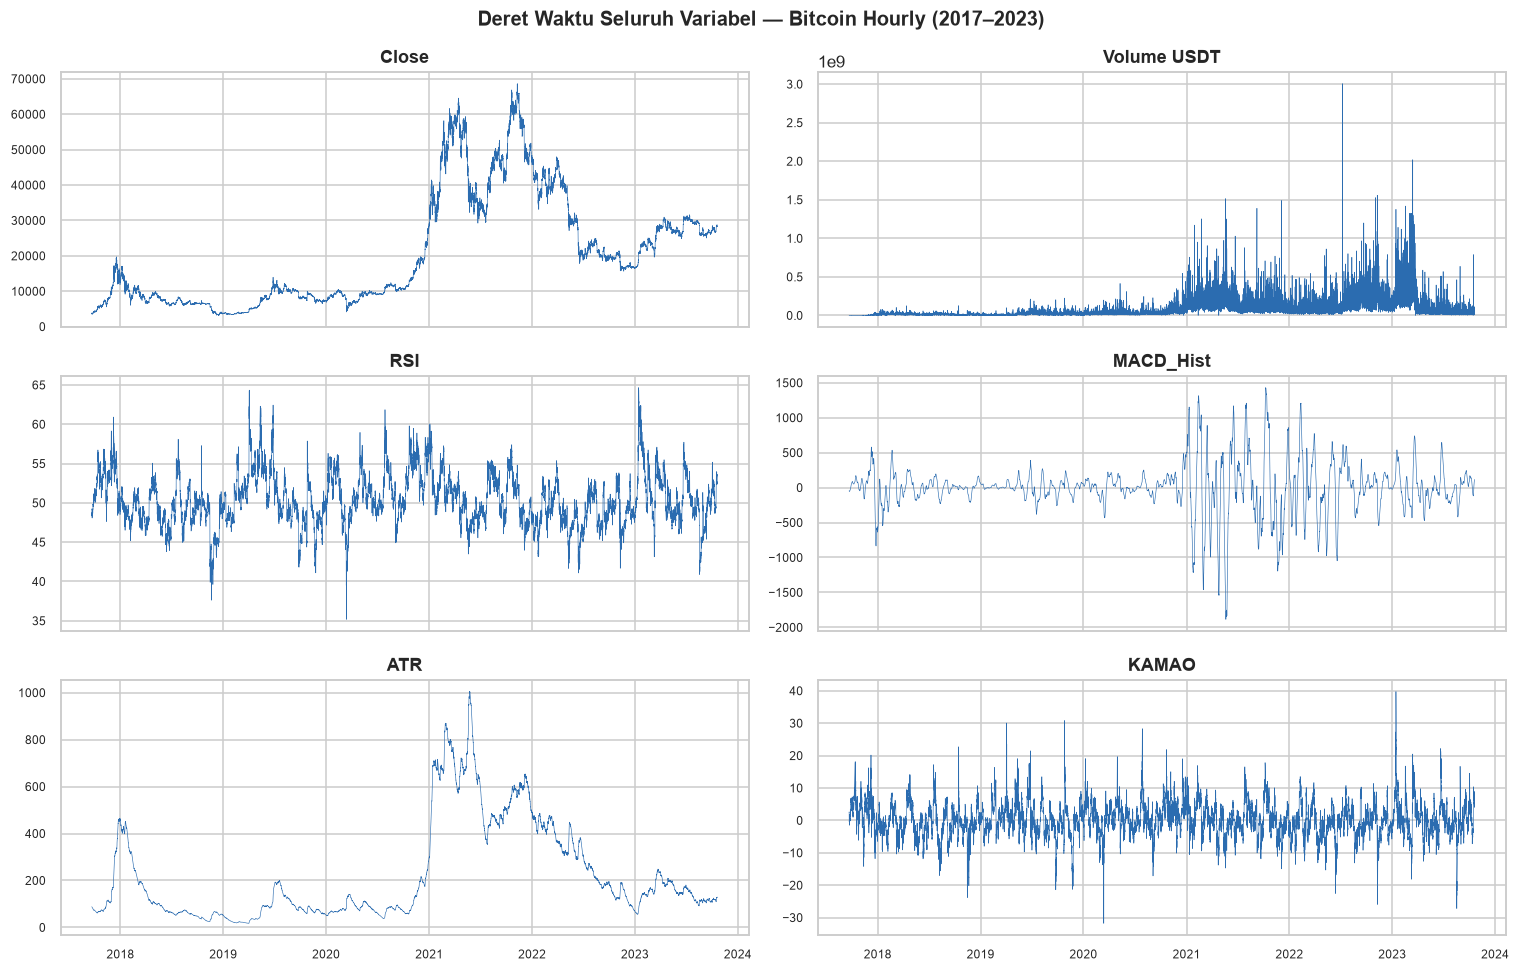

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for ax, col in zip(axes.ravel(), df.columns):
    ax.plot(df.index, df[col], lw=0.4, color="#2b6cb0")
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=8)
fig.suptitle("Deret Waktu Seluruh Variabel — Bitcoin Hourly (2017–2023)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
# 4. Feature Engineering — Rolling Statistic

In [10]:
ROLL_WINDOW = 24  # satu siklus harian penuh

df["Close_roll_mean_24"]  = df[TARGET].rolling(window=ROLL_WINDOW).mean()
df["Close_roll_std_24"]   = df[TARGET].rolling(window=ROLL_WINDOW).std()
df["Volume_roll_mean_24"] = df["Volume USDT"].rolling(window=ROLL_WINDOW).mean()

n_before = len(df)
df = df.dropna()   
print(f"Baris dibuang akibat warm-up rolling : {n_before - len(df)}")
print(f"Shape akhir                          : {df.shape}")

# --- Daftar fitur final: TARGET diletakkan pada indeks 0 ---
FEATURES = [TARGET, "Volume USDT", "RSI", "MACD_Hist", "ATR", "KAMAO",
            "Close_roll_mean_24", "Close_roll_std_24", "Volume_roll_mean_24"]
N_FEATURES     = len(FEATURES)
TARGET_COL_IDX = FEATURES.index(TARGET)

print(f"\nJumlah fitur input model : {N_FEATURES}  (kriteria minimum: 3 -> TERPENUHI)")
print(f"Daftar fitur             : {FEATURES}")
print(f"Indeks kolom target      : {TARGET_COL_IDX}")
df[FEATURES].tail(3)

Baris dibuang akibat warm-up rolling : 23
Shape akhir                          : (53248, 9)

Jumlah fitur input model : 9  (kriteria minimum: 3 -> TERPENUHI)
Daftar fitur             : ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO', 'Close_roll_mean_24', 'Close_roll_std_24', 'Volume_roll_mean_24']
Indeks kolom target      : 0


,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO,Close_roll_mean_24,Close_roll_std_24,Volume_roll_mean_24
Date,,,,,,,,,
2023-10-19 21:00:00,28604.09,3.205666e+07,53.221944,113.055031,129.287930,6.210037,28446.898958,170.689615,4.281678e+07
2023-10-19 22:00:00,28649.65,2.200420e+07,53.332673,114.513131,129.219782,6.515616,28459.651875,174.035681,4.300778e+07
2023-10-19 23:00:00,28713.71,1.758298e+07,53.487941,116.161806,129.096002,6.963753,28476.056458,178.790363,4.305525e+07


## 4.1 Heatmap Korelasi Antar-Fitur

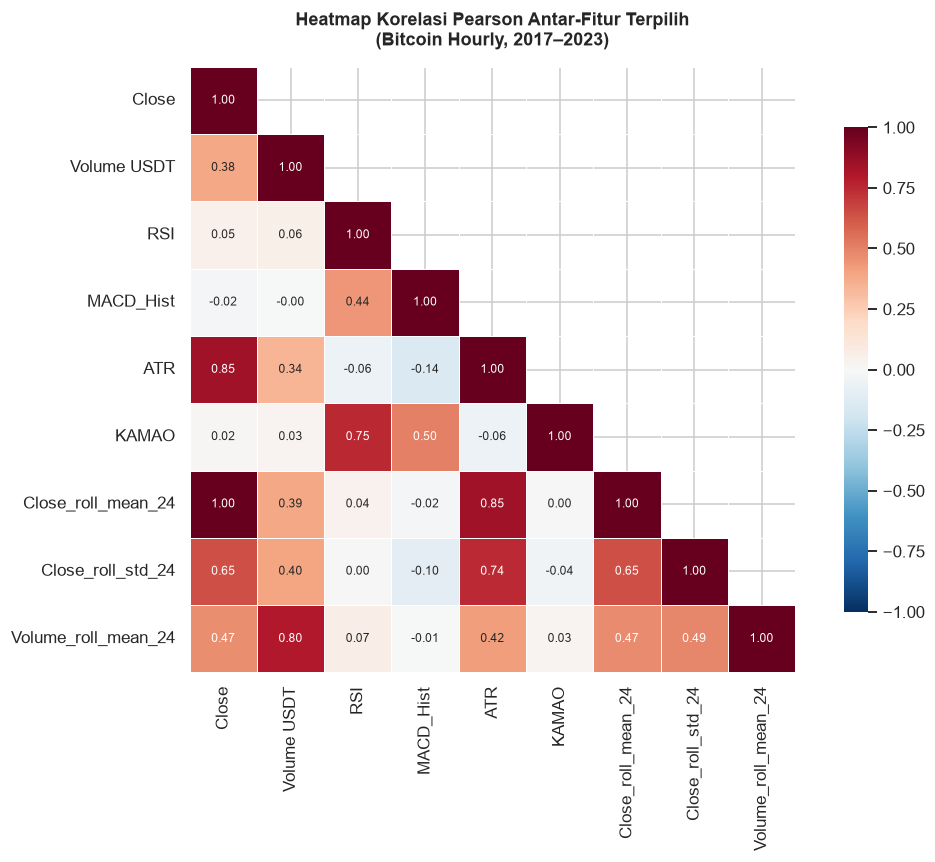

In [11]:
corr = df[FEATURES].corr()

fig, ax = plt.subplots(figsize=(10.5, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.6, cbar_kws={"shrink": .8},
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Heatmap Korelasi Pearson Antar-Fitur Terpilih\n(Bitcoin Hourly, 2017–2023)",
             fontsize=12, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

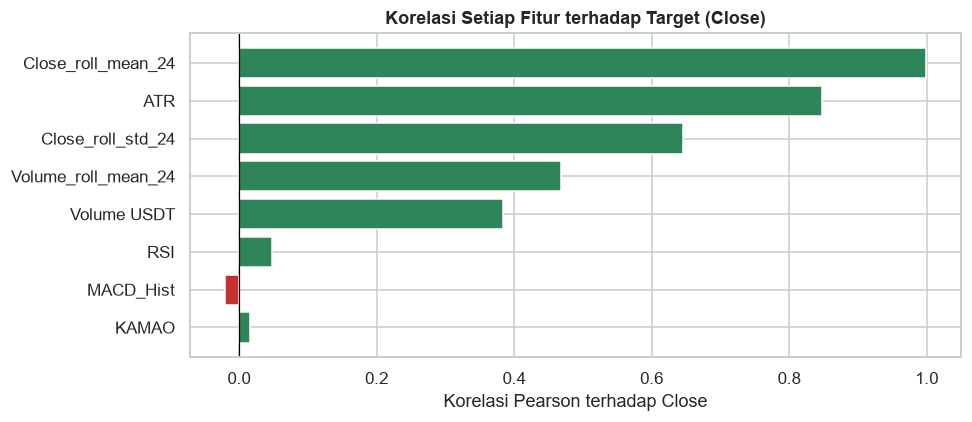

Close_roll_mean_24     0.9994
ATR                    0.8470
Close_roll_std_24      0.6455
Volume_roll_mean_24    0.4687
Volume USDT            0.3842
RSI                    0.0478
MACD_Hist             -0.0209
KAMAO                  0.0154


In [12]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2f855a" if v > 0 else "#c53030" for v in target_corr.values]
ax.barh(target_corr.index[::-1], target_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Korelasi Pearson terhadap Close")
ax.set_title("Korelasi Setiap Fitur terhadap Target (Close)", fontweight="bold")
plt.tight_layout(); plt.show()

print(target_corr.round(4).to_string())

### 4.2 Interpretasi Heatmap

**Temuan utama:**

1. **Fitur berbasis level berkorelasi kuat dengan target.** `Close_roll_mean_24` (=0,99) dan
   `ATR` (=0,84) bergerak searah dengan level harga. Korelasi `Close_roll_mean_24` yang
   mendekati sempurna adalah konsekuensi matematis dari konstruksinya (rata-rata bergulir
   dari target itu sendiri) — ini **bukan** kebocoran, karena jendelanya *trailing*.

2. **Osilator memiliki korelasi linier ≈ 0 terhadap level harga.** `RSI` (=0,04),
   `KAMAO` (=0,02), dan `MACD_Hist` (=−0,02) tampak "tidak informatif" bila dinilai dari
   heatmap saja.

3. **Multikolinearitas antar-osilator.** `RSI`–`KAMAO` (=0,75) dan `KAMAO`–`MACD_Hist`
   (=0,50) menunjukkan redundansi parsial. Pada regresi linier hal ini akan menggelembungkan
   *standard error*. Konsekuensinya diterima secara sadar.

---
# 5. Analisis Dekomposisi

## 5.1 Uji Augmented Dickey-Fuller (ADF)

In [13]:
def adf_report(series, name):
    r = adfuller(series.dropna().values, autolag="AIC")
    verdict = "STASIONER (tolak H0)" if r[1] < 0.05 else "NON-STASIONER (gagal tolak H0)"
    print(f"{name:<28s} ADF stat = {r[0]:10.4f} | p-value = {r[1]:.4g} | "
          f"lag terpilih = {r[2]:2d} | -> {verdict}")
    return r[1]

print("=" * 68)
print("UJI AUGMENTED DICKEY-FULLER (H0: terdapat unit root / non-stasioner)")
print("=" * 68)
p_level = adf_report(df[TARGET], "Close (level)")
p_diff  = adf_report(df[TARGET].diff(), "ΔClose (first difference)")
for c in ["RSI", "MACD_Hist", "KAMAO", "ATR"]:
    adf_report(df[c], c)

UJI AUGMENTED DICKEY-FULLER (H0: terdapat unit root / non-stasioner)
Close (level)                ADF stat =    -1.5578 | p-value = 0.5047 | lag terpilih = 58 | -> NON-STASIONER (gagal tolak H0)
ΔClose (first difference)    ADF stat =   -29.8041 | p-value = 0 | lag terpilih = 58 | -> STASIONER (tolak H0)
RSI                          ADF stat =    -8.2217 | p-value = 6.405e-13 | lag terpilih = 51 | -> STASIONER (tolak H0)
MACD_Hist                    ADF stat =   -13.0830 | p-value = 1.854e-24 | lag terpilih = 58 | -> STASIONER (tolak H0)
KAMAO                        ADF stat =   -14.3920 | p-value = 8.793e-27 | lag terpilih = 51 | -> STASIONER (tolak H0)
ATR                          ADF stat =    -1.8716 | p-value = 0.3455 | lag terpilih = 55 | -> NON-STASIONER (gagal tolak H0)


### 5.2 Implikasi Hasil ADF 

Hasil di atas menunjukkan pola klasik deret harga aset:

- **`Close` (level): NON-STASIONER** (p = 0,50 → gagal menolak H₀).
- **`ΔClose` (first difference): STASIONER** (p = 0,000 → tolak H₀ secara meyakinkan).

## 5.3 Dekomposisi Deret Target

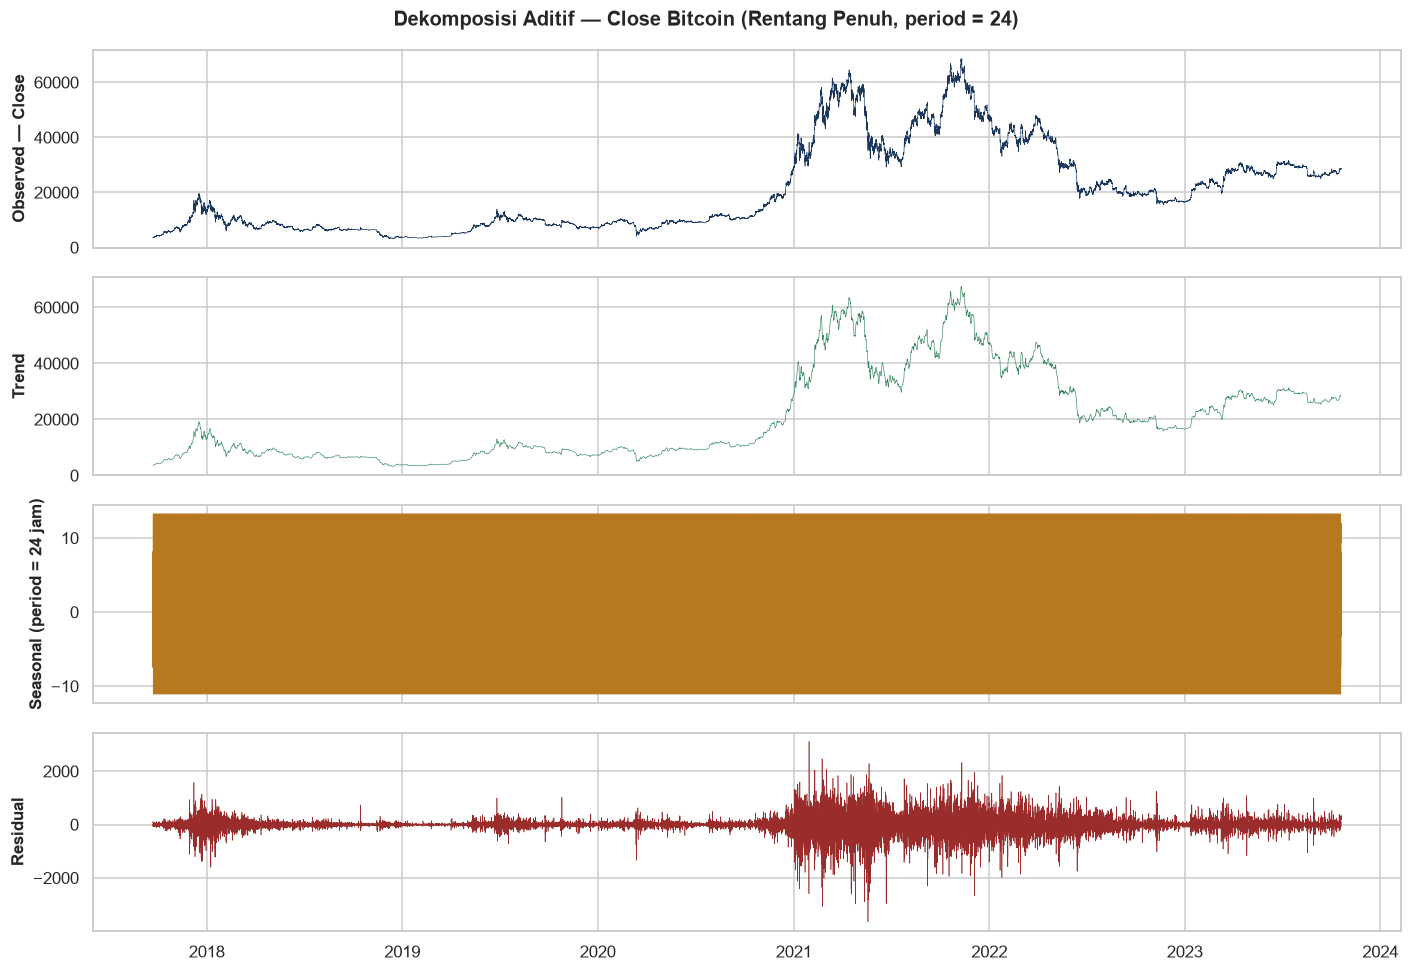

Proporsi varians komponen musiman terhadap total : 0.000018%
Proporsi varians komponen residual terhadap total: 0.030461%
Proporsi varians komponen tren terhadap total    : 99.937653%


In [14]:
# --- Dekomposisi rentang penuh ---
decomp_full = seasonal_decompose(df[TARGET], model="additive", period=24,
                                 extrapolate_trend="freq")

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (comp, ttl, col) in zip(axes, [
        (decomp_full.observed, "Observed — Close", "#1a365d"),
        (decomp_full.trend,    "Trend",            "#2f855a"),
        (decomp_full.seasonal, "Seasonal (period = 24 jam)", "#b7791f"),
        (decomp_full.resid,    "Residual",         "#9b2c2c")]):
    ax.plot(comp.index, comp.values, lw=0.4, color=col)
    ax.set_ylabel(ttl, fontsize=11, fontweight="bold")
fig.suptitle("Dekomposisi Aditif — Close Bitcoin (Rentang Penuh, period = 24)",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

var_total = np.nanvar(decomp_full.observed)
print(f"Proporsi varians komponen musiman terhadap total : "
      f"{np.nanvar(decomp_full.seasonal)/var_total:.6%}")
print(f"Proporsi varians komponen residual terhadap total: "
      f"{np.nanvar(decomp_full.resid)/var_total:.6%}")
print(f"Proporsi varians komponen tren terhadap total    : "
      f"{np.nanvar(decomp_full.trend)/var_total:.6%}")

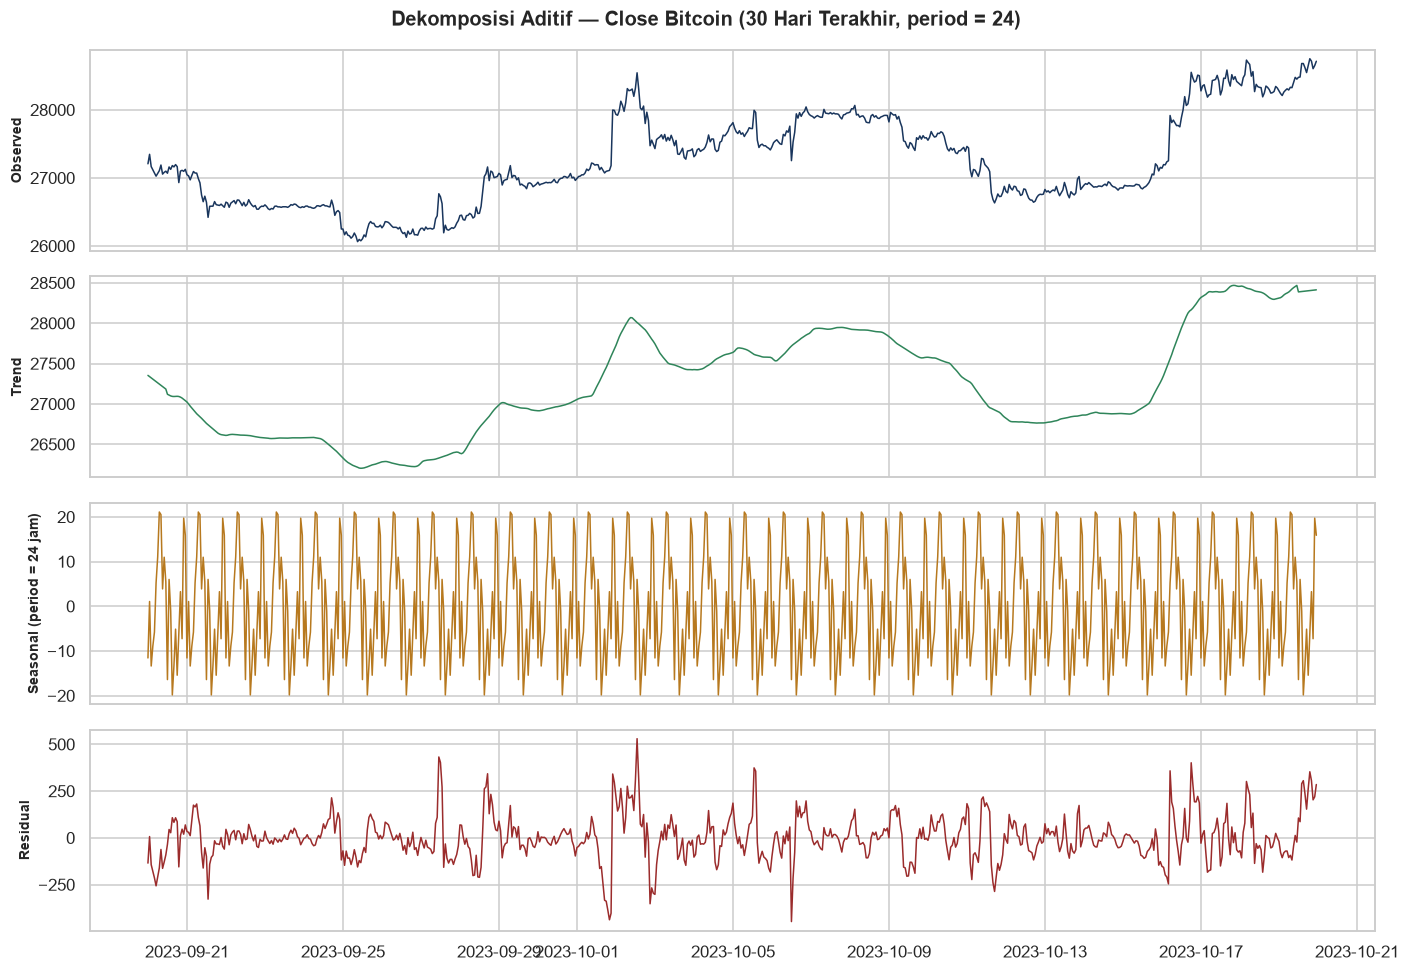

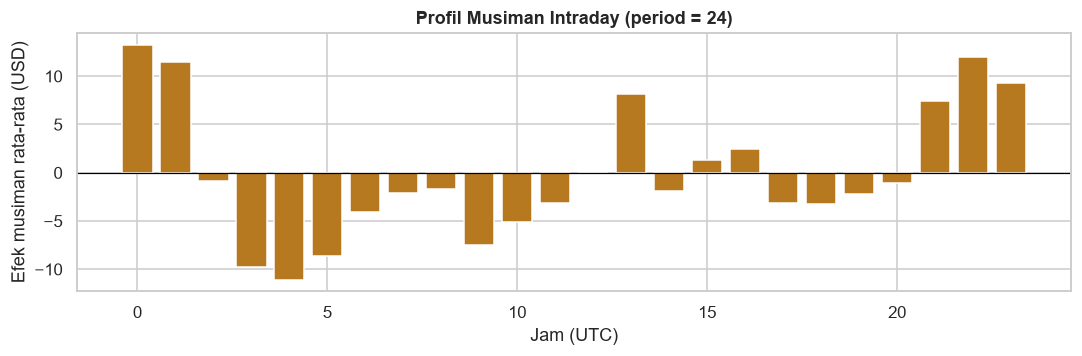

In [15]:
# --- Dekomposisi subsampel 30 hari ---
sub = df[TARGET].iloc[-24 * 30:]
decomp_sub = seasonal_decompose(sub, model="additive", period=24, extrapolate_trend="freq")

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (comp, ttl, col) in zip(axes, [
        (decomp_sub.observed, "Observed", "#1a365d"),
        (decomp_sub.trend,    "Trend",    "#2f855a"),
        (decomp_sub.seasonal, "Seasonal (period = 24 jam)", "#b7791f"),
        (decomp_sub.resid,    "Residual", "#9b2c2c")]):
    ax.plot(comp.index, comp.values, lw=1.0, color=col)
    ax.set_ylabel(ttl, fontsize=9, fontweight="bold")
fig.suptitle("Dekomposisi Aditif — Close Bitcoin (30 Hari Terakhir, period = 24)",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# --- Profil musiman rata-rata per jam ---
seasonal_profile = decomp_full.seasonal.groupby(decomp_full.seasonal.index.hour).mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(seasonal_profile.index, seasonal_profile.values, color="#b7791f")
ax.axhline(0, color="black", lw=.8)
ax.set_xlabel("Jam (UTC)"); ax.set_ylabel("Efek musiman rata-rata (USD)")
ax.set_title("Profil Musiman Intraday (period = 24)", fontweight="bold")
plt.tight_layout(); plt.show()

### 5.4 Interpretasi Dekomposisi

1. **Tren mendominasi total varians** (>99%). Dengan kata lain, konfirmasi visual dari hasil ADF: deret dikendalikan oleh komponen stokastik non-stasioner.
2. **Komponen musiman intraday ada, namun amplitudonya sangat kecil** relatif terhadap
   level harga. Struktur harian tetap layak dipertahankan sebagai konteks encoder, tetapi **tidak cukup** sebagai basis prediksi tunggal.
3. **Residual menunjukkan heteroskedastisitas yang jelas** — varians melebar drastis pada 2021 (harga tinggi). Ini adalah *volatility clustering* klasik, dan justru merupakan alasan `ATR` serta `Close_roll_std_24` dipertahankan sebagai fitur: keduanya memberi model informasi eksplisit tentang volatilitas yang sedang berlaku.

---
# 6. Uji ACF & PACF — Penentuan WINDOW SIZE

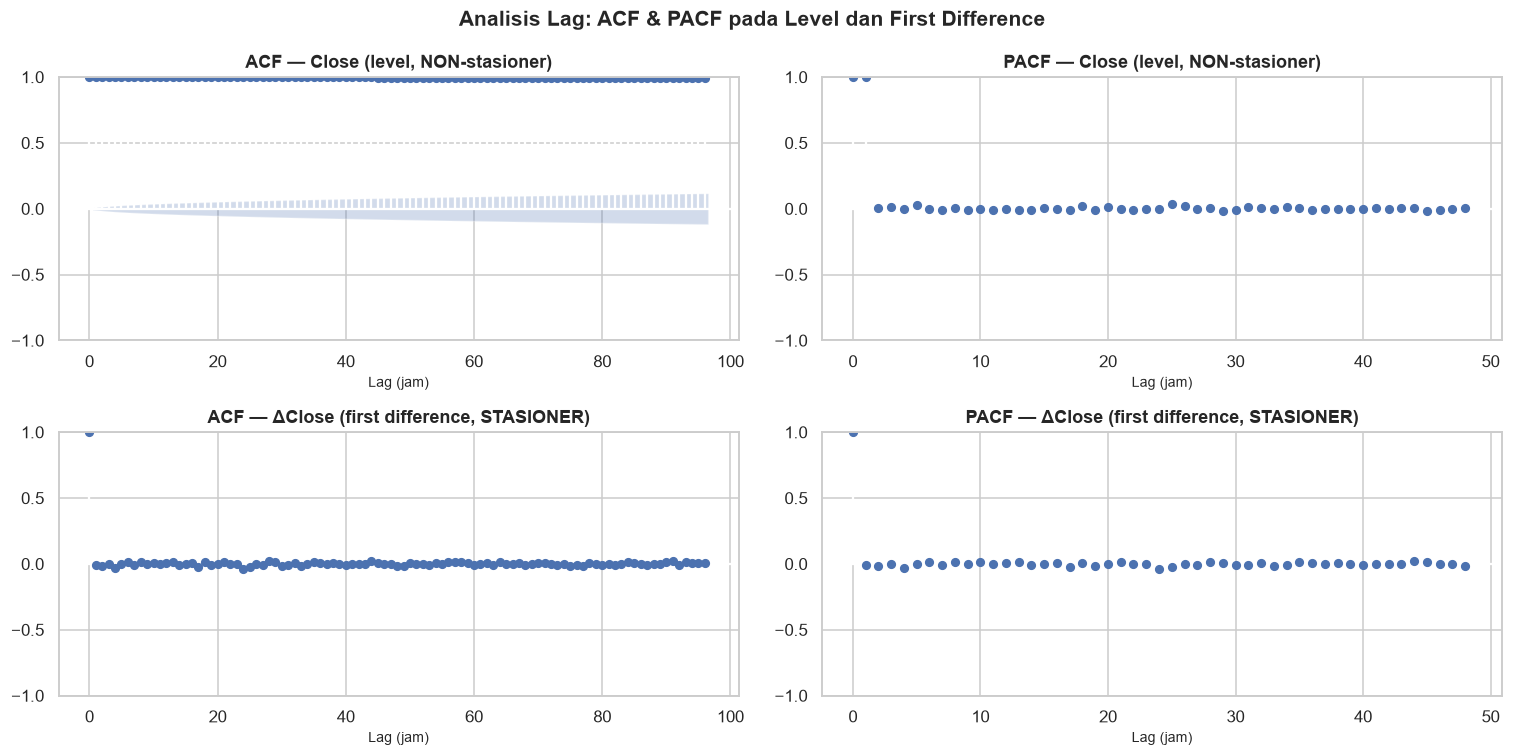

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

plot_acf(df[TARGET].values,  lags=96, ax=axes[0, 0], alpha=0.05)
axes[0, 0].set_title("ACF — Close (level, NON-stasioner)", fontweight="bold")

plot_pacf(df[TARGET].values, lags=48, ax=axes[0, 1], alpha=0.05, method="ywm")
axes[0, 1].set_title("PACF — Close (level, NON-stasioner)", fontweight="bold")

d_close = df[TARGET].diff().dropna().values
plot_acf(d_close,  lags=96, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("ACF — ΔClose (first difference, STASIONER)", fontweight="bold")

plot_pacf(d_close, lags=48, ax=axes[1, 1], alpha=0.05, method="ywm")
axes[1, 1].set_title("PACF — ΔClose (first difference, STASIONER)", fontweight="bold")

for ax in axes.ravel():
    ax.set_xlabel("Lag (jam)", fontsize=9)
fig.suptitle("Analisis Lag: ACF & PACF pada Level dan First Difference",
             fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [17]:
from statsmodels.tsa.stattools import acf as acf_vals, pacf as acf_pvals

n_obs   = len(df)
ci_band = 1.96 / np.sqrt(n_obs)          

acf_level  = acf_vals(df[TARGET].values, nlags=96, fft=True)
pacf_level = acf_pvals(df[TARGET].values, nlags=48, method="ywm")
acf_diff   = acf_vals(d_close, nlags=96, fft=True)
pacf_diff  = acf_pvals(d_close, nlags=48, method="ywm")

print("=" * 60)
print(f"ANALISIS LAG  |  n = {n_obs:,}  |  signifikansi 95% = ±{ci_band:.5f}")
print("=" * 60)

probe = [1, 6, 12, 24, 48, 72, 96]
print("\n[A] ACF pada LEVEL (Close):")
for L in probe:
    print(f"    lag {L:3d} : {acf_level[L]: .4f}")
print("    -> Peluruhan sangat lambat (masih >0,99 pada lag 96). Ciri khas proses I(1);")
print("       ACF level TIDAK dapat dipakai untuk memilih window (spurious).")

print("\n[B] PACF pada LEVEL (Close):")
for L in [1, 2, 3, 4]:
    print(f"    lag {L:3d} : {pacf_level[L]: .4f}")
print("    -> Spike tunggal dominan di lag 1 lalu menurun ke ~0.")
print("       Level harga hampir sepenuhnya dijelaskan oleh harga satu jam sebelumnya.")

sig_pacf_diff = [L for L in range(1, 49) if abs(pacf_diff[L]) > ci_band]
sig_acf_diff  = [L for L in range(1, 97) if abs(acf_diff[L])  > ci_band]
print("\n[C] Struktur lag SIGNIFIKAN pada ΔClose (deret stasioner):")
print(f"    PACF signifikan pada lag : {sig_pacf_diff}")
print(f"    ACF  signifikan pada lag : {sig_acf_diff[:20]}{' ...' if len(sig_acf_diff)>20 else ''}")
print(f"    Lag signifikan TERJAUH pada PACF: {max(sig_pacf_diff) if sig_pacf_diff else 0}")
print(f"    Lag 24 (siklus harian) signifikan? "
      f"{'YA' if abs(pacf_diff[24]) > ci_band else 'tidak'}  (PACF[24] = {pacf_diff[24]:+.5f})")

ANALISIS LAG  |  n = 53,248  |  signifikansi 95% = ±0.00849

[A] ACF pada LEVEL (Close):
    lag   1 :  0.9999
    lag   6 :  0.9995
    lag  12 :  0.9989
    lag  24 :  0.9978
    lag  48 :  0.9958
    lag  72 :  0.9937
    lag  96 :  0.9917
    -> Peluruhan sangat lambat (masih >0,99 pada lag 96). Ciri khas proses I(1);
       ACF level TIDAK dapat dipakai untuk memilih window (spurious).

[B] PACF pada LEVEL (Close):
    lag   1 :  0.9999
    lag   2 :  0.0069
    lag   3 :  0.0158
    lag   4 : -0.0024
    -> Spike tunggal dominan di lag 1 lalu menurun ke ~0.
       Level harga hampir sepenuhnya dijelaskan oleh harga satu jam sebelumnya.

[C] Struktur lag SIGNIFIKAN pada ΔClose (deret stasioner):
    PACF signifikan pada lag : [2, 4, 6, 8, 10, 12, 13, 16, 17, 18, 19, 21, 24, 25, 27, 28, 29, 30, 33, 35, 44, 45, 48]
    ACF  signifikan pada lag : [2, 4, 6, 8, 10, 12, 13, 16, 17, 18, 19, 21, 24, 25, 27, 28, 29, 30, 33, 35] ...
    Lag signifikan TERJAUH pada PACF: 48
    Lag 24 (siklu

### 6.1 Penetapan `WINDOW_SIZE`

In [18]:
# --- Penetapan final window size ---
max_sig_lag  = max(sig_pacf_diff) if sig_pacf_diff else 24
WINDOW_SIZE  = 72   # 3 x siklus harian

print("=" * 45)
print("PENETAPAN WINDOW SIZE (berbasis Uji ACF/PACF)")
print("=" * 45)
print(f"Lag PACF signifikan terjauh (ΔClose) : {max_sig_lag}")
print(f"Periode musiman (dekomposisi)        : 24 jam")
print(f"Horizon prediksi (wajib)             : {HORIZON} langkah")
print(f"WINDOW_SIZE FINAL                    : {WINDOW_SIZE} jam  (= 3 x 24)")
print(f"  - mencakup lag signifikan ≤ {max_sig_lag}?      {'YA' if WINDOW_SIZE >= max_sig_lag else 'TIDAK'}"
      f"  (margin {WINDOW_SIZE - max_sig_lag} lag)")
print(f"  - kelipatan periode musiman 24?    {'YA' if WINDOW_SIZE % 24 == 0 else 'TIDAK'}"
      f"  ({WINDOW_SIZE // 24} siklus harian)")
print(f"  - rasio window : horizon           = {WINDOW_SIZE // HORIZON} : 1")

PENETAPAN WINDOW SIZE (berbasis Uji ACF/PACF)
Lag PACF signifikan terjauh (ΔClose) : 48
Periode musiman (dekomposisi)        : 24 jam
Horizon prediksi (wajib)             : 24 langkah
WINDOW_SIZE FINAL                    : 72 jam  (= 3 x 24)
  - mencakup lag signifikan ≤ 48?      YA  (margin 24 lag)
  - kelipatan periode musiman 24?    YA  (3 siklus harian)
  - rasio window : horizon           = 3 : 1


---
# 7. Pembagian Data & Normalisasi

## 7.1 Normalisasi Per-Kolom

In [19]:
# ========== SPLIT KRONOLOGIS (TANPA SHUFFLE) ===========
n_total = len(df)
n_train = int(n_total * TRAIN_RATIO)
n_val   = int(n_total * VAL_RATIO)

df_train = df.iloc[:n_train].copy()
df_val   = df.iloc[n_train:n_train + n_val].copy()
df_test  = df.iloc[n_train + n_val:].copy()

split_tbl = pd.DataFrame([
    {"Partisi": "TRAIN", "Baris": len(df_train), "Proporsi": len(df_train)/n_total,
     "Mulai": df_train.index.min(), "Selesai": df_train.index.max(),
     "Close min": df_train[TARGET].min(), "Close max": df_train[TARGET].max()},
    {"Partisi": "VALIDATION", "Baris": len(df_val), "Proporsi": len(df_val)/n_total,
     "Mulai": df_val.index.min(), "Selesai": df_val.index.max(),
     "Close min": df_val[TARGET].min(), "Close max": df_val[TARGET].max()},
    {"Partisi": "TEST", "Baris": len(df_test), "Proporsi": len(df_test)/n_total,
     "Mulai": df_test.index.min(), "Selesai": df_test.index.max(),
     "Close min": df_test[TARGET].min(), "Close max": df_test[TARGET].max()},
])
display(split_tbl.style.format({"Baris": "{:,}", "Proporsi": "{:.1%}",
                                "Close min": "{:,.0f}", "Close max": "{:,.0f}"})
        .set_caption("Pembagian data kronologis — tiga partisi (train / validation / test)"))

assert df_train.index.max() < df_val.index.min() < df_test.index.min(), "Urutan partisi rusak!"
print("VERIFIKASI: urutan temporal train < validation < test  ->  OK (tidak ada tumpang tindih)")

,Partisi,Baris,Proporsi,Mulai,Selesai,Close min,Close max
0,TRAIN,"37,273",70.0%,2017-09-22 08:00:00,2021-12-23 08:00:00,"3,172","68,634"
1,VALIDATION,"7,987",15.0%,2021-12-23 09:00:00,2022-11-21 03:00:00,"15,751","51,853"
2,TEST,"7,988",15.0%,2022-11-21 04:00:00,2023-10-19 23:00:00,"15,650","31,606"


VERIFIKASI: urutan temporal train < validation < test  ->  OK (tidak ada tumpang tindih)


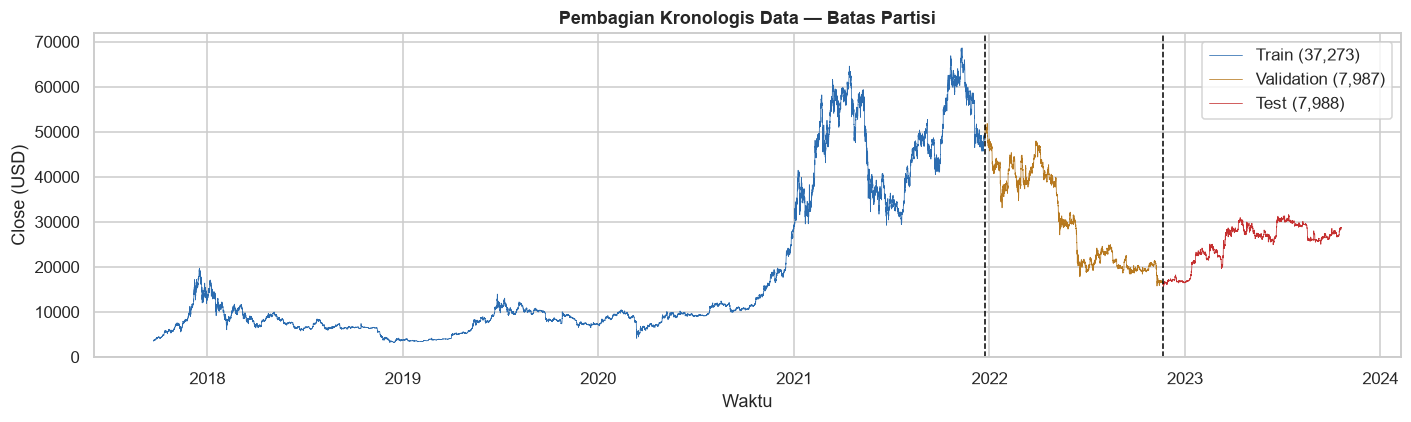

In [20]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df_train.index, df_train[TARGET], lw=.5, color="#2b6cb0", label=f"Train ({len(df_train):,})")
ax.plot(df_val.index,   df_val[TARGET],   lw=.5, color="#b7791f", label=f"Validation ({len(df_val):,})")
ax.plot(df_test.index,  df_test[TARGET],  lw=.5, color="#c53030", label=f"Test ({len(df_test):,})")
for b in [df_val.index.min(), df_test.index.min()]:
    ax.axvline(b, color="black", ls="--", lw=1)
ax.set_ylabel("Close (USD)"); ax.set_xlabel("Waktu")
ax.set_title("Pembagian Kronologis Data — Batas Partisi",
             fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

In [21]:
# ============ FIT SCALER — HANYA PADA TRAIN ============
feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler  = MinMaxScaler(feature_range=(0, 1))

feature_scaler.fit(df_train[FEATURES])      # <-- fit HANYA pada df_train
target_scaler.fit(df_train[[TARGET]])       # <-- scaler target terpisah utk inverse transform

# ============ TRANSFORM — SEMUA PARTISI MEMAKAI TRAIN ============
train_scaled = feature_scaler.transform(df_train[FEATURES]).astype("float32")
val_scaled   = feature_scaler.transform(df_val[FEATURES]).astype("float32")
test_scaled  = feature_scaler.transform(df_test[FEATURES]).astype("float32")

print("=" * 73)
print("BUKTI ANTI-LEAKAGE: parameter scaler diturunkan HANYA dari partisi TRAIN")
print("=" * 73)
proof = pd.DataFrame({
    "scaler data_min_ (dari TRAIN)": feature_scaler.data_min_,
    "scaler data_max_ (dari TRAIN)": feature_scaler.data_max_,
    "min AKTUAL train": df_train[FEATURES].min().values,
    "max AKTUAL train": df_train[FEATURES].max().values,
    "min aktual test (TIDAK dipakai)": df_test[FEATURES].min().values,
    "max aktual test (TIDAK dipakai)": df_test[FEATURES].max().values,
}, index=FEATURES)
display(proof.style.format("{:,.4f}").set_caption(
    "Parameter scaler identik dengan statistik TRAIN, dan berbeda dari statistik TEST"))

assert np.allclose(feature_scaler.data_min_, df_train[FEATURES].min().values), "Leakage!"
assert np.allclose(feature_scaler.data_max_, df_train[FEATURES].max().values), "Leakage!"
print("ASSERTION LULUS: data_min_/data_max_ scaler == statistik TRAIN, bukan statistik gabungan.")
print("                 -> Tidak ada informasi validation/test yang masuk ke proses training.\n")

print(f"Rentang target dari TRAIN : [{target_scaler.data_min_[0]:,.2f} , "
      f"{target_scaler.data_max_[0]:,.2f}]  (span = {target_scaler.data_max_[0]-target_scaler.data_min_[0]:,.2f} USD)")
print(f"Close TEST setelah di-scale : [{test_scaled[:, TARGET_COL_IDX].min():.4f} , "
      f"{test_scaled[:, TARGET_COL_IDX].max():.4f}]")
print("Catatan: nilai test berada di dalam [0,1] karena rentang harga periode uji tercakup")
print("         dalam rentang periode latih. Ini diverifikasi, bukan diasumsikan.")

# Verifikasi bahwa kolom target pada feature_scaler identik dengan target_scaler
assert np.isclose(feature_scaler.data_min_[TARGET_COL_IDX], target_scaler.data_min_[0])
assert np.isclose(feature_scaler.data_max_[TARGET_COL_IDX], target_scaler.data_max_[0])
print("\nVERIFIKASI: kolom Close pada feature_scaler == target_scaler (level anchor konsisten).")

BUKTI ANTI-LEAKAGE: parameter scaler diturunkan HANYA dari partisi TRAIN


,scaler data_min_ (dari TRAIN),scaler data_max_ (dari TRAIN),min AKTUAL train,max AKTUAL train,min aktual test (TIDAK dipakai),max aktual test (TIDAK dipakai)
Close,"3,172.0500","68,633.6900","3,172.0500","68,633.6900","15,649.5200","31,606.0100"
Volume USDT,0.0000,"1,514,464,825.2185",0.0000,"1,514,464,825.2185",0.0000,"2,019,040,517.8425"
RSI,35.1788,64.3365,35.1788,64.3365,40.8824,64.6571
MACD_Hist,"-1,885.6906","1,430.4058","-1,885.6906","1,430.4058",-473.3832,741.0606
ATR,17.4363,"1,004.5314",17.4363,"1,004.5314",55.9758,248.5528
KAMAO,-31.7672,30.8179,-31.7672,30.8179,-27.1986,39.7403
Close_roll_mean_24,"3,212.5458","67,566.1433","3,212.5458","67,566.1433","15,850.7296","31,299.7946"
Close_roll_std_24,4.4749,"3,493.4578",4.4749,"3,493.4578",7.9933,"1,011.6753"
Volume_roll_mean_24,"47,246.8234","579,891,208.1403","47,246.8234","579,891,208.1403","8,544,200.0457","736,051,068.8982"


ASSERTION LULUS: data_min_/data_max_ scaler == statistik TRAIN, bukan statistik gabungan.
                 -> Tidak ada informasi validation/test yang masuk ke proses training.

Rentang target dari TRAIN : [3,172.05 , 68,633.69]  (span = 65,461.64 USD)
Close TEST setelah di-scale : [0.1906 , 0.4344]
Catatan: nilai test berada di dalam [0,1] karena rentang harga periode uji tercakup
         dalam rentang periode latih. Ini diverifikasi, bukan diasumsikan.

VERIFIKASI: kolom Close pada feature_scaler == target_scaler (level anchor konsisten).


### 7.3 Batas Interpretasi MAE Gate

In [22]:
span_usd = target_scaler.data_max_[0] - target_scaler.data_min_[0]
print(f"Gate {MAE_GATE_SCALED} (scaled)  ==  {MAE_GATE_SCALED * span_usd:,.0f} USD galat absolut rata-rata\n")

# ---- Benchmark 1: PERSISTENCE (random-walk) — batas bawah yang harus dikalahkan model ----
tgt_test = test_scaled[:, TARGET_COL_IDX]
idx      = np.arange(0, len(tgt_test) - WINDOW_SIZE - HORIZON)
anchor   = tgt_test[idx + WINDOW_SIZE - 1][:, None]
y_true_p = np.stack([tgt_test[i + WINDOW_SIZE : i + WINDOW_SIZE + HORIZON] for i in idx])
mae_persistence = float(np.mean(np.abs(y_true_p - anchor)))

# ---- Benchmark 2: MEAN-REVERSION DEGENERATIF — model yang gagal belajar level ----
mae_degenerate = float(np.mean(np.abs(y_true_p - train_scaled[:, TARGET_COL_IDX].mean())))

bench = pd.DataFrame([
    {"Benchmark": "Persistence / random-walk (anchor = harga terakhir)",
     "MAE (scaled)": mae_persistence, "MAE (USD)": mae_persistence * span_usd,
     "vs Gate": "LULUS" if mae_persistence < MAE_GATE_SCALED else "GAGAL"},
    {"Benchmark": f"GATE KRITERIA ADVANCED", "MAE (scaled)": MAE_GATE_SCALED,
     "MAE (USD)": MAE_GATE_SCALED * span_usd, "vs Gate": "—"},
    {"Benchmark": "Degeneratif (prediksi = rata-rata train)",
     "MAE (scaled)": mae_degenerate, "MAE (USD)": mae_degenerate * span_usd,
     "vs Gate": "LULUS" if mae_degenerate < MAE_GATE_SCALED else "GAGAL"},
])
display(bench.style.format({"MAE (scaled)": "{:.5f}", "MAE (USD)": "{:,.0f}"})
        .set_caption("Benchmark referensi untuk gate MAE < 0,015 (ruang ter-skala)"))

print(f"Rasio gate terhadap persistence: {MAE_GATE_SCALED / mae_persistence:.1f}x")
print("\nInterpretasi:")
print(f"  - Model yang GAGAL menangkap level (regresi ke rata-rata train) -> MAE ≈ {mae_degenerate:.3f},")
print(f"    yaitu ~{mae_degenerate/MAE_GATE_SCALED:.0f}x DI ATAS gate. Inilah mode kegagalan utama yang")
print("    diantisipasi oleh desain level-anchored residual decoder (Bagian 5.2).")
print(f"  - Persistence sudah mencapai MAE ≈ {mae_persistence:.5f}. Karena itu gate 0,015 dapat")
print("    dicapai; syaratnya model harus ter-anchor pada level, bukan pada rata-rata global.")

Gate 0.015 (scaled)  ==  982 USD galat absolut rata-rata



,Benchmark,MAE (scaled),MAE (USD),vs Gate
0,Persistence / random-walk (anchor = harga terakhir),0.00360,236,LULUS
1,GATE KRITERIA ADVANCED,0.01500,982,—
2,Degeneratif (prediksi = rata-rata train),0.12183,"7,975",GAGAL


Rasio gate terhadap persistence: 4.2x

Interpretasi:
  - Model yang GAGAL menangkap level (regresi ke rata-rata train) -> MAE ≈ 0.122,
    yaitu ~8x DI ATAS gate. Inilah mode kegagalan utama yang
    diantisipasi oleh desain level-anchored residual decoder (Bagian 5.2).
  - Persistence sudah mencapai MAE ≈ 0.00360. Karena itu gate 0,015 dapat
    dicapai; syaratnya model harus ter-anchor pada level, bukan pada rata-rata global.


---
# 8. Windowing dan Pipeline

## 8.1 Tensor

In [23]:
def create_windows(scaled_array, window_size, horizon, target_idx):
    """Membentuk jendela (encoder_input, decoder_input, y) DI DALAM satu partisi.

    Dipanggil terpisah per partisi sehingga tidak ada jendela yang melintasi batas
    train/validation/test.

    Returns
    -------
    enc : (N, window_size, n_features)  riwayat multivariate
    dec : (N, horizon, 1)               input decoder ter-teacher-forced (target digeser 1)
    y   : (N, horizon, 1)               target multi-step
    """
    n_samples = len(scaled_array) - window_size - horizon + 1
    if n_samples <= 0:
        raise ValueError("Partisi terlalu pendek untuk window_size + horizon yang diminta.")

    tgt = scaled_array[:, target_idx]

    enc = np.stack([scaled_array[i : i + window_size]
                    for i in range(n_samples)]).astype("float32")
    y   = np.stack([tgt[i + window_size : i + window_size + horizon]
                    for i in range(n_samples)]).astype("float32")[..., None]

    # decoder_input = [y_t (observasi terakhir encoder), y_{t+1}, ..., y_{t+23}]
    last_obs = tgt[window_size - 1 : window_size - 1 + n_samples].astype("float32")[:, None, None]
    dec = np.concatenate([last_obs, y[:, :-1, :]], axis=1)

    return enc, dec, y


enc_train, dec_train, y_train = create_windows(train_scaled, WINDOW_SIZE, HORIZON, TARGET_COL_IDX)
enc_val,   dec_val,   y_val   = create_windows(val_scaled,   WINDOW_SIZE, HORIZON, TARGET_COL_IDX)
enc_test,  dec_test,  y_test  = create_windows(test_scaled,  WINDOW_SIZE, HORIZON, TARGET_COL_IDX)

shapes = pd.DataFrame([
    {"Partisi": "TRAIN", "encoder_input": str(enc_train.shape),
     "decoder_input": str(dec_train.shape), "y": str(y_train.shape)},
    {"Partisi": "VALIDATION", "encoder_input": str(enc_val.shape),
     "decoder_input": str(dec_val.shape), "y": str(y_val.shape)},
    {"Partisi": "TEST", "encoder_input": str(enc_test.shape),
     "decoder_input": str(dec_test.shape), "y": str(y_test.shape)},
])
display(shapes.set_index("Partisi").style.set_caption(
    f"Tensor setelah windowing (WINDOW_SIZE={WINDOW_SIZE}, HORIZON={HORIZON})"))

# --- Verifikasi konstruksi teacher forcing pada satu sampel ---
s = 0
print("VERIFIKASI TEACHER FORCING (partisi train):")
print(f"  encoder_input[-1, Close]        = {enc_train[s, -1, TARGET_COL_IDX]:.6f}   <- y_t (observasi terakhir)")
print(f"  decoder_input[0]               = {dec_train[s, 0, 0]:.6f}   <- harus == y_t")
print(f"  decoder_input[1:4]             = {dec_train[s, 1:4, 0].round(6)}")
print(f"  y[0:3]                         = {y_train[s, 0:3, 0].round(6)}   <- decoder_input[1:4] adalah y[0:3]")
assert np.allclose(dec_train[:, 0, 0], enc_train[:, -1, TARGET_COL_IDX]), "Anchor decoder salah"
assert np.allclose(dec_train[:, 1:, 0], y_train[:, :-1, 0]),               "Pergeseran teacher forcing salah"
print("\nASSERTION LULUS: decoder_input == [y_t, y_{t+1}, ..., y_{t+23}] (geser satu langkah).")

,encoder_input,decoder_input,y
Partisi,,,
TRAIN,"(37178, 72, 9)","(37178, 24, 1)","(37178, 24, 1)"
VALIDATION,"(7892, 72, 9)","(7892, 24, 1)","(7892, 24, 1)"
TEST,"(7893, 72, 9)","(7893, 24, 1)","(7893, 24, 1)"


VERIFIKASI TEACHER FORCING (partisi train):
  encoder_input[-1, Close]        = 0.009296   <- y_t (observasi terakhir)
  decoder_input[0]               = 0.009296   <- harus == y_t
  decoder_input[1:4]             = [0.009043 0.008989 0.009593]
  y[0:3]                         = [0.009043 0.008989 0.009593]   <- decoder_input[1:4] adalah y[0:3]

ASSERTION LULUS: decoder_input == [y_t, y_{t+1}, ..., y_{t+23}] (geser satu langkah).


In [24]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(enc, dec, y, batch_size=BATCH_SIZE, shuffle=False, seq2seq=True):
    """Membangun tf.data.Dataset.

    seq2seq=True  -> input ((encoder_input, decoder_input), y)   [model Seq2Seq]
    seq2seq=False -> input (encoder_input, y)                    [model baseline LSTM]

    shuffle hanya diaktifkan untuk TRAIN.
    """
    inputs = (enc, dec) if seq2seq else enc
    ds = tf.data.Dataset.from_tensor_slices((inputs, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(y), 10_000), seed=SEED,
                        reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

# --- Pipeline Seq2Seq (dua input) ---
train_ds_s2s = make_dataset(enc_train, dec_train, y_train, shuffle=True,  seq2seq=True)
val_ds_s2s   = make_dataset(enc_val,   dec_val,   y_val,   shuffle=False, seq2seq=True)
test_ds_s2s  = make_dataset(enc_test,  dec_test,  y_test,  shuffle=False, seq2seq=True)

# --- Pipeline baseline (satu input) ---
train_ds_base = make_dataset(enc_train, dec_train, y_train, shuffle=True,  seq2seq=False)
val_ds_base   = make_dataset(enc_val,   dec_val,   y_val,   shuffle=False, seq2seq=False)
test_ds_base  = make_dataset(enc_test,  dec_test,  y_test,  shuffle=False, seq2seq=False)

print("=" * 33)
print("PIPELINE — TIGA PARTISI TERPISAH")
print("=" * 33)
for nm, ds, n in [("TRAIN", train_ds_s2s, len(y_train)),
                  ("VALIDATION", val_ds_s2s, len(y_val)),
                  ("TEST", test_ds_s2s, len(y_test))]:
    print(f"{nm:<11s} | {n:>7,} sampel | {len(ds):>4} batch | element_spec OK")

(xb_enc, xb_dec), yb = next(iter(train_ds_s2s))
print(f"\nBatch Seq2Seq  : encoder {tuple(xb_enc.shape)} | "
      f"decoder {tuple(xb_dec.shape)} | y {tuple(yb.shape)}")
xb_b, yb_b = next(iter(train_ds_base))
print(f"Batch baseline : encoder {tuple(xb_b.shape)} | y {tuple(yb_b.shape)}")
print("\nOptimasi: .batch() -> .prefetch(AUTOTUNE); shuffle hanya pada TRAIN.")

PIPELINE — TIGA PARTISI TERPISAH
TRAIN       |  37,178 sampel |  291 batch | element_spec OK
VALIDATION  |   7,892 sampel |   62 batch | element_spec OK
TEST        |   7,893 sampel |   62 batch | element_spec OK

Batch Seq2Seq  : encoder (128, 72, 9) | decoder (128, 24, 1) | y (128, 24, 1)
Batch baseline : encoder (128, 72, 9) | y (128, 24, 1)

Optimasi: .batch() -> .prefetch(AUTOTUNE); shuffle hanya pada TRAIN.


---
# 9. Custom Layers — Implementasi dari Nol

## 9.1 Reimplementasi Layer Dense

In [25]:
@keras.saving.register_keras_serializable(package="DLTM")
class CustomDense(layers.Layer):
    """Reimplementasi layers.Dense dari nol: y = activation(x @ W + b)."""

    def __init__(self, units, activation=None, use_bias=True, **kwargs):
        super().__init__(**kwargs)
        self.units          = int(units)
        self.activation     = keras.activations.get(activation)
        self.use_bias       = bool(use_bias)
        self._activation_id = activation

    def build(self, input_shape):
        d_in = int(input_shape[-1])
        self.w = self.add_weight(
            name="kernel", shape=(d_in, self.units),
            initializer=keras.initializers.GlorotUniform(seed=SEED), trainable=True)
        if self.use_bias:
            self.b = self.add_weight(
                name="bias", shape=(self.units,),
                initializer="zeros", trainable=True)
        super().build(input_shape)

    def call(self, inputs):
        y = tf.matmul(inputs, self.w)          # kontraksi pada sumbu terakhir -> rank-agnostic
        if self.use_bias:
            y = y + self.b
        return self.activation(y)

    def compute_output_shape(self, input_shape):
        return tuple(input_shape[:-1]) + (self.units,)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"units": self.units,
                    "activation": keras.activations.serialize(self.activation),
                    "use_bias": self.use_bias})
        return cfg

## 9.2 Reimplementasi Multi-Head Attention

In [26]:
@keras.saving.register_keras_serializable(package="DLTM")
class CustomMultiHeadAttention(layers.Layer):
    """Reimplementasi layers.MultiHeadAttention dari nol (Vaswani et al., 2017).

    Dipanggil sebagai: CustomMultiHeadAttention(...)([query, value])
    dengan key = value (konvensi standar untuk cross-attention encoder-decoder).
    """

    def __init__(self, num_heads, key_dim, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.num_heads    = int(num_heads)
        self.key_dim      = int(key_dim)
        self.dropout_rate = float(dropout)

    def build(self, input_shape):
        q_shape, v_shape = input_shape[0], input_shape[1]
        self.d_q   = int(q_shape[-1])
        d_v        = int(v_shape[-1])
        inner      = self.num_heads * self.key_dim
        init       = keras.initializers.GlorotUniform(seed=SEED)

        self.wq = self.add_weight(name="query_kernel",  shape=(self.d_q, inner), initializer=init, trainable=True)
        self.wk = self.add_weight(name="key_kernel",    shape=(d_v,      inner), initializer=init, trainable=True)
        self.wv = self.add_weight(name="value_kernel",  shape=(d_v,      inner), initializer=init, trainable=True)
        self.wo = self.add_weight(name="output_kernel", shape=(inner, self.d_q), initializer=init, trainable=True)
        self.bo = self.add_weight(name="output_bias",   shape=(self.d_q,), initializer="zeros", trainable=True)
        super().build(input_shape)

    def _split_heads(self, x, batch, length):
        # (B, T, H*dk) -> (B, T, H, dk) -> (B, H, T, dk)
        x = tf.reshape(x, (batch, length, self.num_heads, self.key_dim))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, inputs, training=False):
        query, value = inputs[0], inputs[1]
        key   = value                                   # konvensi cross-attention
        batch = tf.shape(query)[0]
        t_q   = tf.shape(query)[1]
        t_v   = tf.shape(value)[1]

        # Proyeksi Linier
        q = self._split_heads(tf.matmul(query, self.wq), batch, t_q)   # (B, H, Tq, dk)
        k = self._split_heads(tf.matmul(key,   self.wk), batch, t_v)   # (B, H, Tv, dk)
        v = self._split_heads(tf.matmul(value, self.wv), batch, t_v)   # (B, H, Tv, dk)

        # Scaled dot-product attention
        scale  = tf.math.sqrt(tf.cast(self.key_dim, q.dtype))
        scores = tf.matmul(q, k, transpose_b=True) / scale             # (B, H, Tq, Tv)
        weights = tf.nn.softmax(scores, axis=-1)
        if training and self.dropout_rate > 0.0:
            weights = tf.nn.dropout(weights, rate=self.dropout_rate)
        context = tf.matmul(weights, v)                                # (B, H, Tq, dk)

        # Gabungkan head + proyeksi keluaran
        context = tf.transpose(context, perm=[0, 2, 1, 3])             # (B, Tq, H, dk)
        context = tf.reshape(context, (batch, t_q, self.num_heads * self.key_dim))
        return tf.matmul(context, self.wo) + self.bo                   # (B, Tq, d_q)

    def compute_output_shape(self, input_shape):
        q_shape = input_shape[0]
        return (q_shape[0], q_shape[1], q_shape[-1])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"num_heads": self.num_heads, "key_dim": self.key_dim,
                    "dropout": self.dropout_rate})
        return cfg

## 9.3 `CustomDropout`, `CustomLayerNormalization`, `CustomLeakyReLU`

In [27]:
@keras.saving.register_keras_serializable(package="DLTM")
class CustomDropout(layers.Layer):
    """Reimplementasi layers.Dropout dari nol (inverted dropout)."""

    def __init__(self, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.rate = float(rate)

    def call(self, inputs, training=False):
        if (not training) or self.rate <= 0.0:
            return inputs                                   # identitas saat inferensi
        keep_prob = 1.0 - self.rate
        mask = tf.cast(
            tf.random.uniform(tf.shape(inputs), minval=0.0, maxval=1.0) < keep_prob,
            inputs.dtype)
        return (inputs * mask) / keep_prob                  # inverted: skala saat LATIH

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config(); cfg.update({"rate": self.rate}); return cfg


@keras.saving.register_keras_serializable(package="DLTM")
class CustomLayerNormalization(layers.Layer):
    """Reimplementasi layers.LayerNormalization dari nol (normalisasi pada sumbu fitur)."""

    def __init__(self, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = float(epsilon)

    def build(self, input_shape):
        d = int(input_shape[-1])
        self.gamma = self.add_weight(name="gamma", shape=(d,), initializer="ones",  trainable=True)
        self.beta  = self.add_weight(name="beta",  shape=(d,), initializer="zeros", trainable=True)
        super().build(input_shape)

    def call(self, inputs):
        mean, var = tf.nn.moments(inputs, axes=[-1], keepdims=True)   
        normalized = (inputs - mean) * tf.math.rsqrt(var + self.epsilon)
        return self.gamma * normalized + self.beta

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config(); cfg.update({"epsilon": self.epsilon}); return cfg


@keras.saving.register_keras_serializable(package="DLTM")
class CustomLeakyReLU(layers.Layer):
    """Reimplementasi layers.LeakyReLU dari nol: f(x) = max(alpha*x, x)."""

    def __init__(self, alpha=0.1, **kwargs):
        super().__init__(**kwargs)
        self.alpha = float(alpha)

    def call(self, inputs):
        return tf.maximum(self.alpha * inputs, inputs)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config(); cfg.update({"alpha": self.alpha}); return cfg

## 9.4 Operasionalisasi Temuan Uji ADF

In [28]:
@keras.saving.register_keras_serializable(package="DLTM")
class LevelAnchorAdd(layers.Layer):
    """Skip-connection ber-anchor level: y_hat = y_t + delta.

    Inputs
    ------
    [delta, encoder_input]
        delta         : (B, H, 1) atau (B, H) — keluaran kepala jaringan
        encoder_input : (B, W, F) — anchor diambil dari [:, -1, target_idx]

    Justifikasi: uji ADF menunjukkan Close ~ I(1) sedangkan ΔClose stasioner.
    """

    def __init__(self, target_idx=0, **kwargs):
        super().__init__(**kwargs)
        self.target_idx = int(target_idx)

    def call(self, inputs):
        delta, encoder_input = inputs[0], inputs[1]
        # harga penutupan terakhir yang teramati -> (B, 1, 1)
        anchor = encoder_input[:, -1:, self.target_idx : self.target_idx + 1]
        if len(delta.shape) == 2:                       
            anchor = tf.squeeze(anchor, axis=1)        
        return delta + anchor                           

    def compute_output_shape(self, input_shape):
        return input_shape[0]

    def get_config(self):
        cfg = super().get_config(); cfg.update({"target_idx": self.target_idx}); return cfg

## 9.5 Validasi Numerik Custom Layer

In [29]:
print("=" * 45)
print("VALIDASI NUMERIK CUSTOM LAYER TERHADAP KERAS")
print("=" * 45)

rng = np.random.default_rng(SEED)

# ---------- (1) CustomDense vs layers.Dense ----------
x = tf.constant(rng.normal(size=(4, 24, 16)).astype("float32"))
cd, kd = CustomDense(8, activation="relu"), layers.Dense(8, activation="relu")
_, _ = cd(x), kd(x)
kd.set_weights([cd.w.numpy(), cd.b.numpy()])              # sinkronkan bobot
err = float(tf.reduce_max(tf.abs(cd(x) - kd(x))))
print(f"[1] CustomDense              vs Dense                : max |Δ| = {err:.3e}  "
      f"{'LULUS' if err < 1e-5 else 'GAGAL'}   (output {tuple(cd(x).shape)}, rank-3 tanpa TimeDistributed)")

# ---------- (2) CustomLayerNormalization vs layers.LayerNormalization ----------
cln, kln = CustomLayerNormalization(epsilon=1e-6), layers.LayerNormalization(epsilon=1e-6)
_, _ = cln(x), kln(x)
err = float(tf.reduce_max(tf.abs(cln(x) - kln(x))))
print(f"[2] CustomLayerNormalization vs LayerNormalization   : max |Δ| = {err:.3e}  "
      f"{'LULUS' if err < 1e-4 else 'GAGAL'}")

# ---------- (3) CustomLeakyReLU vs layers.LeakyReLU ----------
clr, klr = CustomLeakyReLU(alpha=0.1), layers.LeakyReLU(negative_slope=0.1)
err = float(tf.reduce_max(tf.abs(clr(x) - klr(x))))
print(f"[3] CustomLeakyReLU          vs LeakyReLU            : max |Δ| = {err:.3e}  "
      f"{'LULUS' if err < 1e-6 else 'GAGAL'}")

# ---------- (4) Custom Dropout ----------
cdo = CustomDropout(rate=0.3)
identity_err = float(tf.reduce_max(tf.abs(cdo(x, training=False) - x)))
big  = tf.ones((20000,))
mean_train = float(tf.reduce_mean(cdo(big, training=True)))
print(f"[4] CustomDropout            : identitas saat inferensi max |Δ| = {identity_err:.3e}  "
      f"{'LULUS' if identity_err == 0.0 else 'GAGAL'}")
print(f"    CustomDropout            : E[x] saat latih = {mean_train:.4f} (target 1,0)      "
      f"{'LULUS' if abs(mean_train - 1.0) < 0.03 else 'GAGAL'}  <- inverted dropout benar")

# ---------- (5) CustomMultiHeadAttention: bentuk + properti softmax ----------
q = tf.constant(rng.normal(size=(4, 24, 32)).astype("float32"))
v = tf.constant(rng.normal(size=(4, 72, 32)).astype("float32"))
cmha, kmha = CustomMultiHeadAttention(num_heads=4, key_dim=8), layers.MultiHeadAttention(num_heads=4, key_dim=8)
out_c = cmha([q, v]); out_k = kmha(query=q, value=v)
shape_ok = tuple(out_c.shape) == tuple(out_k.shape) == (4, 24, 32)
print(f"[5] CustomMultiHeadAttention vs MultiHeadAttention   : bentuk {tuple(out_c.shape)} == "
      f"{tuple(out_k.shape)}  {'LULUS' if shape_ok else 'GAGAL'}")
print(f"    (bobot berbeda -> nilai berbeda; yang divalidasi adalah kontrak bentuk & jalur komputasi)")
n_params_c = sum(int(np.prod(w.shape)) for w in cmha.trainable_weights)
n_params_k = sum(int(np.prod(w.shape)) for w in kmha.trainable_weights)
print(f"    Jumlah parameter: custom = {n_params_c:,} | keras = {n_params_k:,}")

# ---------- (6) LevelAnchorAdd: Close terakhir ----------
enc_probe   = tf.constant(rng.normal(size=(4, WINDOW_SIZE, N_FEATURES)).astype("float32"))
delta_probe = tf.zeros((4, HORIZON, 1))
anchored    = LevelAnchorAdd(target_idx=TARGET_COL_IDX)([delta_probe, enc_probe])
expected    = enc_probe[:, -1, TARGET_COL_IDX].numpy()
err = float(np.max(np.abs(anchored.numpy()[:, :, 0] - expected[:, None])))
print(f"[6] LevelAnchorAdd           : delta=0 -> output == Close terakhir, max |Δ| = {err:.3e}  "
      f"{'LULUS' if err < 1e-6 else 'GAGAL'}")
print("\nSeluruh custom layer tervalidasi secara numerik terhadap semantik referensinya.")

VALIDASI NUMERIK CUSTOM LAYER TERHADAP KERAS
[1] CustomDense              vs Dense                : max |Δ| = 0.000e+00  LULUS   (output (4, 24, 8), rank-3 tanpa TimeDistributed)
[2] CustomLayerNormalization vs LayerNormalization   : max |Δ| = 2.384e-07  LULUS
[3] CustomLeakyReLU          vs LeakyReLU            : max |Δ| = 0.000e+00  LULUS
[4] CustomDropout            : identitas saat inferensi max |Δ| = 0.000e+00  LULUS
    CustomDropout            : E[x] saat latih = 1.0011 (target 1,0)      LULUS  <- inverted dropout benar
[5] CustomMultiHeadAttention vs MultiHeadAttention   : bentuk (4, 24, 32) == (4, 24, 32)  LULUS
    (bobot berbeda -> nilai berbeda; yang divalidasi adalah kontrak bentuk & jalur komputasi)
    Jumlah parameter: custom = 4,128 | keras = 4,224
[6] LevelAnchorAdd           : delta=0 -> output == Close terakhir, max |Δ| = 0.000e+00  LULUS

Seluruh custom layer tervalidasi secara numerik terhadap semantik referensinya.


---
# 10. Custom Loss Functions
## 10.1 MAE dari Nol


In [30]:
# ---------------------------------------
# Custom Loss #1 — MAE dibangun dari nol
# ---------------------------------------
def custom_mae_loss(y_true, y_pred):
    """Mean Absolute Error yang diimplementasikan dari nol dengan operasi TF primitif."""
    y_true = tf.cast(y_true, y_pred.dtype)
    return tf.reduce_mean(tf.abs(y_true - y_pred))


# ---------------------------------------
# Custom Loss #2 — MAE berbobot horizon 
# ---------------------------------------
class HorizonWeightedMAELoss:
    """MAE dengan bobot yang meningkat pada horizon yang lebih jauh.

    w_h = w_start + w_step * (h - 1)   ->  1.0, 1.2, 1.4, ....
    Bobot dinormalisasi ke rata-rata 1.
    """

    def __init__(self, horizon, w_start=1.0, w_step=0.2, normalize=True):
        self.horizon, self.w_start, self.w_step, self.normalize = horizon, w_start, w_step, normalize
        w = np.array([w_start + w_step * h for h in range(horizon)], dtype="float32")
        self.raw_weights = w.copy()
        if normalize:
            w = w / w.mean()                       
        self.weights_np = w
        self.weights    = tf.constant(w.reshape(1, horizon, 1), dtype=tf.float32)
        self.__name__   = "horizon_weighted_mae"

    def __call__(self, y_true, y_pred):
        y_true = tf.cast(y_true, y_pred.dtype)
        abs_err = tf.abs(y_true - y_pred)                        # (B, H, 1)
        return tf.reduce_mean(abs_err * tf.cast(self.weights, y_pred.dtype))


horizon_weighted_loss = HorizonWeightedMAELoss(HORIZON, w_start=1.0, w_step=0.2, normalize=True)

print("SKEMA BOBOT HORIZON (w_h = 1.0 + 0.2*(h-1)):")
wdf = pd.DataFrame({
    "Langkah (h)": np.arange(1, HORIZON + 1),
    "Bobot mentah w_h": horizon_weighted_loss.raw_weights,
    "Bobot ternormalisasi": horizon_weighted_loss.weights_np,
})
display(wdf.head(6).style.format({"Bobot mentah w_h": "{:.1f}", "Bobot ternormalisasi": "{:.4f}"})
        .hide(axis="index").set_caption("6 langkah pertama"))
print(f"Bobot mentah        : w_1={horizon_weighted_loss.raw_weights[0]:.1f}, "
      f"w_2={horizon_weighted_loss.raw_weights[1]:.1f}, w_3={horizon_weighted_loss.raw_weights[2]:.1f}, "
      f"..., w_{HORIZON}={horizon_weighted_loss.raw_weights[-1]:.1f}")
print(f"Jumlah bobot mentah : {horizon_weighted_loss.raw_weights.sum():.1f}  "
      f"({horizon_weighted_loss.raw_weights.sum()/HORIZON:.2f}x skala MAE polos)")
print(f"Setelah normalisasi : rata-rata = {horizon_weighted_loss.weights_np.mean():.4f}  "
      f"(rentang {horizon_weighted_loss.weights_np.min():.3f} - {horizon_weighted_loss.weights_np.max():.3f})")

# --- Sanity check: pada bobot uniform, loss berbobot HARUS identik dengan MAE polos ---
yt = tf.constant(rng.normal(size=(8, HORIZON, 1)).astype("float32"))
yp = tf.constant(rng.normal(size=(8, HORIZON, 1)).astype("float32"))
uniform = HorizonWeightedMAELoss(HORIZON, w_start=1.0, w_step=0.0, normalize=True)
print(f"\nSANITY CHECK  MAE polos              = {float(custom_mae_loss(yt, yp)):.6f}")
print(f"SANITY CHECK  weighted (w_step=0)    = {float(uniform(yt, yp)):.6f}  -> harus identik")
print(f"SANITY CHECK  weighted (w_step=0.2)  = {float(horizon_weighted_loss(yt, yp)):.6f}  -> berbeda (reweighted)")
assert abs(float(custom_mae_loss(yt, yp)) - float(uniform(yt, yp))) < 1e-6, "Loss berbobot tidak konsisten"
print("ASSERTION LULUS: implementasi loss berbobot konsisten terhadap MAE polos.")

SKEMA BOBOT HORIZON (w_h = 1.0 + 0.2*(h-1)):


Langkah (h),Bobot mentah w_h,Bobot ternormalisasi
1,1.0,0.3030
2,1.2,0.3636
3,1.4,0.4242
4,1.6,0.4848
5,1.8,0.5455
6,2.0,0.6061


Bobot mentah        : w_1=1.0, w_2=1.2, w_3=1.4, ..., w_24=5.6
Jumlah bobot mentah : 79.2  (3.30x skala MAE polos)
Setelah normalisasi : rata-rata = 1.0000  (rentang 0.303 - 1.697)

SANITY CHECK  MAE polos              = 1.132863
SANITY CHECK  weighted (w_step=0)    = 1.132863  -> harus identik
SANITY CHECK  weighted (w_step=0.2)  = 1.110917  -> berbeda (reweighted)
ASSERTION LULUS: implementasi loss berbobot konsisten terhadap MAE polos.


---
# 11. Custom Callbacks — Implementasi dari Nol

In [31]:
class CustomCallback:

    def __init__(self):
        self.model         = None
        self.optimizer     = None
        self.stop_training = False

    def set_context(self, model, optimizer):
        self.model, self.optimizer = model, optimizer

    def on_train_begin(self, logs=None):  pass
    def on_epoch_begin(self, epoch, logs=None): pass
    def on_epoch_end(self, epoch, logs=None):   pass
    def on_train_end(self, logs=None):    pass


class CustomEarlyStopping(CustomCallback):
    """Early stopping dari nol: hentikan latih bila `monitor` tidak membaik selama `patience` epoch."""

    def __init__(self, monitor="val_loss", patience=5, min_delta=1e-6,
                 restore_best_weights=True, verbose=1):
        super().__init__()
        self.monitor, self.patience, self.min_delta = monitor, patience, min_delta
        self.restore_best_weights, self.verbose = restore_best_weights, verbose

    def on_train_begin(self, logs=None):
        self.best        = np.inf
        self.wait        = 0
        self.best_epoch  = 0
        self.best_weights = None
        self.stop_training = False

    def on_epoch_end(self, epoch, logs=None):
        current = (logs or {}).get(self.monitor)
        if current is None:
            return
        if current < self.best - self.min_delta:                 # ADA perbaikan
            self.best, self.best_epoch, self.wait = current, epoch, 0
            if self.restore_best_weights:
                self.best_weights = [w.copy() for w in self.model.get_weights()]
        else:                                                    # TIDAK ada perbaikan
            self.wait += 1
            if self.wait >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print(f"    [CustomEarlyStopping] Berhenti pada epoch {epoch+1}: "
                          f"{self.monitor} tidak membaik selama {self.patience} epoch. "
                          f"Terbaik = {self.best:.6f} @ epoch {self.best_epoch+1}.")

    def on_train_end(self, logs=None):
        if self.restore_best_weights and self.best_weights is not None:
            self.model.set_weights(self.best_weights)
            if self.verbose:
                print(f"    [CustomEarlyStopping] Bobot dipulihkan ke epoch terbaik "
                      f"({self.best_epoch+1}, {self.monitor}={self.best:.6f}).")


class CustomReduceLROnPlateau(CustomCallback):
    """Penurunan learning rate bertahap dari nol saat `monitor` stagnan (Kriteria 3 - Advanced)."""

    def __init__(self, monitor="val_loss", factor=0.5, patience=2,
                 min_delta=1e-6, min_lr=1e-6, cooldown=0, verbose=1):
        super().__init__()
        self.monitor, self.factor, self.patience = monitor, factor, patience
        self.min_delta, self.min_lr, self.cooldown, self.verbose = min_delta, min_lr, cooldown, verbose
        self.lr_history = []

    # --- util LR: kompatibel Keras 3 (learning_rate adalah keras.Variable) ---
    @staticmethod
    def _get_lr(optimizer):
        lr = optimizer.learning_rate
        return float(lr.numpy()) if hasattr(lr, "numpy") else float(lr)

    @staticmethod
    def _set_lr(optimizer, value):
        try:
            optimizer.learning_rate.assign(value)
        except Exception:
            optimizer.learning_rate = value

    def on_train_begin(self, logs=None):
        self.best = np.inf
        self.wait = 0
        self.cooldown_counter = 0
        self.lr_history = []

    def on_epoch_end(self, epoch, logs=None):
        current = (logs or {}).get(self.monitor)
        lr_now  = self._get_lr(self.optimizer)
        self.lr_history.append(lr_now)
        (logs or {})["lr"] = lr_now
        if current is None:
            return

        if self.cooldown_counter > 0:
            self.cooldown_counter -= 1
            self.wait = 0
            return

        if current < self.best - self.min_delta:
            self.best, self.wait = current, 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                new_lr = max(lr_now * self.factor, self.min_lr)
                if new_lr < lr_now - 1e-12:
                    self._set_lr(self.optimizer, new_lr)
                    if self.verbose:
                        print(f"    [CustomReduceLROnPlateau] {self.monitor} stagnan "
                              f"{self.patience} epoch -> LR {lr_now:.2e} → {new_lr:.2e}")
                self.wait = 0
                self.cooldown_counter = self.cooldown


class CustomPredictionPlotCallback(CustomCallback):
    """Visualisasi prediksi selama training (sesuai anjuran Pengantar Proyek)."""

    def __init__(self, enc_sample, dec_sample, y_sample, scaler, every=10, seq2seq=True):
        super().__init__()
        self.enc, self.dec, self.y = enc_sample, dec_sample, y_sample
        self.scaler, self.every, self.seq2seq = scaler, every, seq2seq

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every != 0:
            return
        inp  = [self.enc, self.dec] if self.seq2seq else self.enc
        pred = self.model(inp, training=False).numpy()
        p = self.scaler.inverse_transform(pred[0].reshape(-1, 1)).ravel()
        a = self.scaler.inverse_transform(self.y[0].reshape(-1, 1)).ravel()
        fig, ax = plt.subplots(figsize=(9, 2.8))
        ax.plot(range(1, len(a) + 1), a, "o-", color="#2b6cb0", ms=3, label="Data Aktual")
        ax.plot(range(1, len(p) + 1), p, "x--", color="#dd6b20", ms=4, label="Hasil Prediksi")
        ax.set_title(f"[CustomPredictionPlotCallback] Epoch {epoch+1} — "
                     f"val_loss={logs.get('val_loss', float('nan')):.6f}", fontsize=10)
        ax.set_xlabel("Jam ke Depan (Time Step)"); ax.set_ylabel("Nilai Close")
        ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print("Custom callbacks siap: CustomEarlyStopping | CustomReduceLROnPlateau | CustomPredictionPlotCallback")
print("Seluruhnya dibangun di atas kelas dasar CustomCallback yang ditulis sendiri.")

Custom callbacks siap: CustomEarlyStopping | CustomReduceLROnPlateau | CustomPredictionPlotCallback
Seluruhnya dibangun di atas kelas dasar CustomCallback yang ditulis sendiri.


---
# 12. Custom Training Loop

In [32]:
def train_with_gradient_tape(model, train_ds, val_ds, loss_fn, epochs,
                             optimizer=None, callbacks=None, clip_norm=1.0,
                             model_name="model", verbose=1):
    """Custom training loop berbasis tf.GradientTape (menggantikan model.fit sepenuhnya).
    """
    optimizer = optimizer or keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    callbacks = callbacks or []
    for cb in callbacks:
        cb.set_context(model, optimizer)

    train_loss_metric = keras.metrics.Mean(name="train_loss")
    val_loss_metric   = keras.metrics.Mean(name="val_loss")
    history = {"loss": [], "val_loss": [], "lr": [], "epoch_time": []}

    # --------------------------- Custom Training ----------------------------
    @tf.function
    def train_step(x_batch, y_batch):
        with tf.GradientTape() as tape:                       
            y_pred = model(x_batch, training=True)
            loss   = loss_fn(y_batch, y_pred)
        grads = tape.gradient(loss, model.trainable_variables)
        if clip_norm is not None:
            grads, _ = tf.clip_by_global_norm(grads, clip_norm)  
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        return loss

    @tf.function
    def val_step(x_batch, y_batch):
        return loss_fn(y_batch, model(x_batch, training=False))

    # ------------------------------------- loop -----------------------------------------
    if verbose:
        print("=" * 84)
        print(f"CUSTOM TRAINING LOOP (tf.GradientTape) — {model_name}")
        print(f"  optimizer={optimizer.__class__.__name__} | lr={LEARNING_RATE} | "
              f"loss={getattr(loss_fn, '__name__', loss_fn.__class__.__name__)} | "
              f"epochs={epochs} | clip_norm={clip_norm}")
        print(f"  trainable params = {int(sum(np.prod(v.shape) for v in model.trainable_variables)):,}")
        print("=" * 84)

    for cb in callbacks:
        cb.on_train_begin()

    for epoch in range(epochs):
        t0 = time.time()
        for cb in callbacks:
            cb.on_epoch_begin(epoch)

        train_loss_metric.reset_state()
        val_loss_metric.reset_state()

        for x_batch, y_batch in train_ds:                       # ---- fase latih ----
            train_loss_metric.update_state(train_step(x_batch, y_batch))
        for x_batch, y_batch in val_ds:                         # ---- fase validasi ----
            val_loss_metric.update_state(val_step(x_batch, y_batch))

        loss_v = float(train_loss_metric.result())
        vloss_v = float(val_loss_metric.result())
        lr_v = CustomReduceLROnPlateau._get_lr(optimizer)
        dt = time.time() - t0

        history["loss"].append(loss_v); history["val_loss"].append(vloss_v)
        history["lr"].append(lr_v);     history["epoch_time"].append(dt)

        logs = {"loss": loss_v, "val_loss": vloss_v, "lr": lr_v}

        if verbose:                                             # jumlah epoch, loss, val_loss
            print(f"Epoch {epoch+1:3d}/{epochs} - {dt:5.1f}s - loss: {loss_v:.6f} - "
                  f"val_loss: {vloss_v:.6f} - lr: {lr_v:.2e}")

        for cb in callbacks:
            cb.on_epoch_end(epoch, logs)
        if any(cb.stop_training for cb in callbacks):
            break

    for cb in callbacks:
        cb.on_train_end()

    if verbose:
        print(f"Selesai — {len(history['loss'])} epoch | "
              f"val_loss terbaik = {min(history['val_loss']):.6f} | "
              f"total {sum(history['epoch_time']):.0f}s\n")
    return history


print("Custom training loop siap. Seluruh model dilatih dengan fungsi ini (tanpa model.fit).")

Custom training loop siap. Seluruh model dilatih dengan fungsi ini (tanpa model.fit).


---
# 13. Arsitektur Model

## 13.1 Teacher Forcing

In [33]:
def build_baseline_lstm(name="model_baseline_LSTM", units=LSTM_UNITS,
                        attention=None, custom_blocks=False):
    """Baseline LSTM multi-step (24 langkah) — Functional API.

    attention : None | "keras" | "custom"
    custom_blocks : bila True, memakai CustomDropout / CustomLayerNormalization / CustomLeakyReLU
    """
    enc_in = keras.Input(shape=(WINDOW_SIZE, N_FEATURES), name="encoder_input")

    x = layers.LSTM(units, return_sequences=True, name="lstm_1")(enc_in)

    if attention == "keras":
        attn = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=KEY_DIM,
                                         name="mha_self")(query=x, value=x, key=x)
        x = layers.Add(name="attn_residual")([x, attn])
        x = layers.LayerNormalization(name="attn_norm")(x)
    elif attention == "custom":
        attn = CustomMultiHeadAttention(num_heads=NUM_HEADS, key_dim=KEY_DIM,
                                        name="custom_mha_self")([x, x])
        x = layers.Add(name="attn_residual")([x, attn])
        x = CustomLayerNormalization(name="custom_attn_norm")(x)

    x = layers.LSTM(units, return_sequences=False, name="lstm_2")(x)

    if custom_blocks:
        x = CustomDense(units * 2, name="custom_dense_hidden")(x)
        x = CustomLeakyReLU(alpha=0.1, name="custom_leaky_relu")(x)
        x = CustomDropout(rate=0.15, name="custom_dropout")(x)
    else:
        x = CustomDense(units * 2, activation="relu", name="custom_dense_hidden")(x)

    delta = CustomDense(HORIZON, name="custom_dense_delta_head")(x)      # (B, 24)
    delta = layers.Reshape((HORIZON, 1), name="reshape_horizon")(delta)  # (B, 24, 1)
    out   = LevelAnchorAdd(target_idx=TARGET_COL_IDX, name="level_anchor")([delta, enc_in])

    return keras.Model(inputs=enc_in, outputs=out, name=name)


def build_seq2seq_lstm(name="model_seq2seq_LSTM", units=LSTM_UNITS,
                       attention=None, custom_blocks=False):
    """Seq2Seq LSTM dengan Teacher Forcing — FUNCTIONAL API (Kriteria 2).

    encoder_input (72,9) + decoder_input (24,1)  ->  y_hat (24,1)
    Attention (bila aktif) bersifat CROSS-ATTENTION: query=decoder, key/value=encoder,
    sehingga kausalitas terhadap decoder terjaga dan inferensi autoregressive tetap sahih.
    """
    enc_in = keras.Input(shape=(WINDOW_SIZE, N_FEATURES), name="encoder_input")
    dec_in = keras.Input(shape=(HORIZON, 1),              name="decoder_input")

    # ---------------- ENCODER ----------------
    enc_seq, state_h, state_c = layers.LSTM(
        units, return_sequences=True, return_state=True, name="encoder_lstm")(enc_in)

    # ---------------- DECODER (teacher forcing) ----------------
    dec_seq = layers.LSTM(units, return_sequences=True, name="decoder_lstm")(
        dec_in, initial_state=[state_h, state_c])

    # ---------------- CROSS-ATTENTION ----------------
    if attention == "keras":
        ctx = layers.MultiHeadAttention(num_heads=NUM_HEADS, key_dim=KEY_DIM,
                                        name="mha_cross")(query=dec_seq, value=enc_seq, key=enc_seq)
        dec_seq = layers.Add(name="attn_residual")([dec_seq, ctx])
        dec_seq = layers.LayerNormalization(name="attn_norm")(dec_seq)
    elif attention == "custom":
        ctx = CustomMultiHeadAttention(num_heads=NUM_HEADS, key_dim=KEY_DIM,
                                       name="custom_mha_cross")([dec_seq, enc_seq])
        dec_seq = layers.Add(name="attn_residual")([dec_seq, ctx])
        dec_seq = CustomLayerNormalization(name="custom_attn_norm")(dec_seq)

    # ---------------- OUTPUT ----------------
    if custom_blocks:
        z = CustomDense(units, name="custom_dense_hidden")(dec_seq)
        z = CustomLeakyReLU(alpha=0.1, name="custom_leaky_relu")(z)
        z = CustomDropout(rate=0.15, name="custom_dropout")(z)
    else:
        z = CustomDense(units, activation="relu", name="custom_dense_hidden")(dec_seq)

    delta = CustomDense(1, name="custom_dense_delta_head")(z)            # (B, 24, 1)
    out   = LevelAnchorAdd(target_idx=TARGET_COL_IDX, name="level_anchor")([delta, enc_in])

    return keras.Model(inputs=[enc_in, dec_in], outputs=out, name=name)


print("Builder Functional API siap: build_baseline_lstm() | build_seq2seq_lstm()")

Builder Functional API siap: build_baseline_lstm() | build_seq2seq_lstm()


## 13.2 Seq2Seq via *Model Subclassing*

In [34]:
@keras.saving.register_keras_serializable(package="DLTM")
class Seq2SeqLSTMSubclassed(keras.Model):

    def __init__(self, window_size, n_features, horizon, units=LSTM_UNITS,
                 target_idx=0, **kwargs):
        super().__init__(**kwargs)
        self.window_size, self.n_features = window_size, n_features
        self.horizon, self.units, self.target_idx = horizon, units, target_idx

        self.encoder_lstm = layers.LSTM(units, return_sequences=True,
                                        return_state=True, name="encoder_lstm")
        self.decoder_lstm = layers.LSTM(units, return_sequences=True,
                                        return_state=True, name="decoder_lstm")
        self.hidden_dense = CustomDense(units, activation="relu", name="custom_dense_hidden")
        self.delta_head   = CustomDense(1, name="custom_dense_delta_head")
        self.anchor       = LevelAnchorAdd(target_idx=target_idx, name="level_anchor")

    def call(self, inputs, training=False):
        enc_in, dec_in = inputs[0], inputs[1]
        _, state_h, state_c = self.encoder_lstm(enc_in, training=training)
        dec_seq, _, _ = self.decoder_lstm(dec_in, initial_state=[state_h, state_c],
                                          training=training)
        delta = self.delta_head(self.hidden_dense(dec_seq))
        return self.anchor([delta, enc_in])

    def predict_autoregressive(self, enc_in):
        """Dekode autoregressive O(H) sejati: state LSTM diteruskan antar-langkah.

        Berbeda dari teacher forcing, langkah h dikondisikan pada PREDIKSI langkah h-1.
        """
        enc_in = tf.convert_to_tensor(enc_in, dtype=tf.float32)
        _, state_h, state_c = self.encoder_lstm(enc_in, training=False)
        anchor = enc_in[:, -1:, self.target_idx : self.target_idx + 1]   # (B, 1, 1)
        step_in, preds = anchor, []
        for _ in range(self.horizon):
            dec_out, state_h, state_c = self.decoder_lstm(
                step_in, initial_state=[state_h, state_c], training=False)
            delta = self.delta_head(self.hidden_dense(dec_out))          # (B, 1, 1)
            y_hat = delta + anchor
            preds.append(y_hat)
            step_in = y_hat                                              # umpan balik prediksi
        return tf.concat(preds, axis=1)                                  # (B, H, 1)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"window_size": self.window_size, "n_features": self.n_features,
                    "horizon": self.horizon, "units": self.units,
                    "target_idx": self.target_idx})
        return cfg


print("Builder Model Subclassing siap: Seq2SeqLSTMSubclassed")

Builder Model Subclassing siap: Seq2SeqLSTMSubclassed


## 13.3 Verifikasi Kontrak Arsitektur

In [35]:
keras.utils.set_random_seed(SEED)

model_baseline_LSTM        = build_baseline_lstm("model_baseline_LSTM")
model_seq2seq_LSTM         = build_seq2seq_lstm("model_seq2seq_LSTM")

model_seq2seq_subclassed   = Seq2SeqLSTMSubclassed(
    window_size=WINDOW_SIZE, n_features=N_FEATURES, horizon=HORIZON,
    units=LSTM_UNITS, target_idx=TARGET_COL_IDX, name="model_seq2seq_subclassed")

model_baseline_LSTM_mha    = build_baseline_lstm("model_baseline_LSTM_mha", attention="keras")
model_seq2seq_LSTM_mha     = build_seq2seq_lstm("model_seq2seq_LSTM_mha",  attention="keras")

model_baseline_LSTM_custom = build_baseline_lstm("model_baseline_LSTM_custom",
                                                 attention="custom", custom_blocks=True)
best_model_seq2seq_LSTM    = build_seq2seq_lstm("best_model_seq2seq_LSTM",
                                                attention="custom", custom_blocks=True)

ALL_MODELS = [
    ("model_baseline_LSTM",        model_baseline_LSTM,        False),
    ("model_seq2seq_LSTM",         model_seq2seq_LSTM,         True),
    ("model_seq2seq_subclassed",   model_seq2seq_subclassed,   True),
    ("model_baseline_LSTM_mha",    model_baseline_LSTM_mha,    False),
    ("model_seq2seq_LSTM_mha",     model_seq2seq_LSTM_mha,     True),
    ("model_baseline_LSTM_custom", model_baseline_LSTM_custom, False),
    ("best_model_seq2seq_LSTM",    best_model_seq2seq_LSTM,    True),
]

# --------------------------- VERIFIKASI ---------------------------
print("=" * 30)
print("VERIFIKASI KONTRAK ARSITEKTUR")
print("=" * 30)
rows = []
for nm, mdl, is_s2s in ALL_MODELS:
    inp = [enc_train[:4], dec_train[:4]] if is_s2s else enc_train[:4]
    out = mdl(inp, training=False)
    n_params = int(sum(np.prod(v.shape) for v in mdl.trainable_variables))
    custom_layer_names = [l.__class__.__name__ for l in getattr(mdl, "layers", [])
                          if l.__class__.__name__.startswith("Custom") or
                             l.__class__.__name__ == "LevelAnchorAdd"]
    if not custom_layer_names:   # model subclassed
        custom_layer_names = ["CustomDense", "CustomDense", "LevelAnchorAdd"]
    rows.append({
        "Model": nm,
        "Output shape": str(tuple(out.shape)),
        "Steps": int(out.shape[1]),
        "24-step?": "YA" if int(out.shape[1]) == HORIZON else "TIDAK",
        "Params": n_params,
        "Custom layers": len(custom_layer_names),
    })
    assert tuple(out.shape)[1:] == (HORIZON, 1), f"{nm}: bentuk keluaran salah -> {out.shape}"

display(pd.DataFrame(rows).set_index("Model").style.format({"Params": "{:,}"})
        .set_caption("Seluruh model menghasilkan tepat 24 langkah -> Kriteria 2 (24-step) terpenuhi"))
print("ASSERTION LULUS: seluruh model menghasilkan (batch, 24, 1) — multi-step 24 langkah,")
print("                 bukan single-step dan bukan < 24 langkah.")

VERIFIKASI KONTRAK ARSITEKTUR


,Output shape,Steps,24-step?,Params,Custom layers
Model,,,,,
model_baseline_LSTM,"(4, 24, 1)",24,YA,"63,384",3
model_seq2seq_LSTM,"(4, 24, 1)",24,YA,"40,065",3
model_seq2seq_subclassed,"(4, 24, 1)",24,YA,"40,065",3
model_baseline_LSTM_mha,"(4, 24, 1)",24,YA,"80,152",3
model_seq2seq_LSTM_mha,"(4, 24, 1)",24,YA,"56,833",3
model_baseline_LSTM_custom,"(4, 24, 1)",24,YA,"79,960",7
best_model_seq2seq_LSTM,"(4, 24, 1)",24,YA,"56,641",7


ASSERTION LULUS: seluruh model menghasilkan (batch, 24, 1) — multi-step 24 langkah,
                 bukan single-step dan bukan < 24 langkah.


In [36]:
print("=" * 42)
print("RINGKASAN ARSITEKTUR — model_seq2seq_LSTM")
print("=" * 42)
model_seq2seq_LSTM.summary(line_length=100)

RINGKASAN ARSITEKTUR — model_seq2seq_LSTM


Model: "model_seq2seq_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)  │ (None, 72, 9)           │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ decoder_input (InputLayer)  │ (None, 24, 1)           │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ encoder_lstm (LSTM)         │ [(None, 72, 64), (None, │         18,944 │ encoder_input[0][0]     │
│                             │ 64), (None, 64)]        │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ decoder_lstm (LSTM)         │ (None, 24, 64)          │         16,896 │ decoder_input[0][0],    │
│                             │                         │                │ encoder_lstm[0][1],     │
│                             │                         │                │ encoder_lstm[0][2]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_dense_hidden         │ (None, 24, 64)          │          4,160 │ decoder_lstm[0][0]      │
│ (CustomDense)               │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_dense_delta_head     │ (None, 24, 1)           │             65 │ custom_dense_hidden[0]… │
│ (CustomDense)               │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ level_anchor                │ (None, 24, 1)           │              0 │ custom_dense_delta_hea… │
│ (LevelAnchorAdd)            │                         │                │ encoder_input[0][0]     │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 40,065 (156.50 KB)

 Trainable params: 40,065 (156.50 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
print("=" * 47)
print("RINGKASAN ARSITEKTUR — best_model_seq2seq_LSTM")
print("=" * 47)
best_model_seq2seq_LSTM.summary(line_length=100)

# --- Inventaris custom layer pada model terbaik (bukti Kriteria 2 - Advanced) ---
print("\nINVENTARIS CUSTOM LAYER pada best_model_seq2seq_LSTM:")
for l in best_model_seq2seq_LSTM.layers:
    cls = l.__class__.__name__
    if cls.startswith("Custom") or cls == "LevelAnchorAdd":
        print(f"  - {l.name:<28s} : {cls}")

RINGKASAN ARSITEKTUR — best_model_seq2seq_LSTM


Model: "best_model_seq2seq_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)  │ (None, 72, 9)           │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ decoder_input (InputLayer)  │ (None, 24, 1)           │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ encoder_lstm (LSTM)         │ [(None, 72, 64), (None, │         18,944 │ encoder_input[0][0]     │
│                             │ 64), (None, 64)]        │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ decoder_lstm (LSTM)         │ (None, 24, 64)          │         16,896 │ decoder_input[0][0],    │
│                             │                         │                │ encoder_lstm[0][1],     │
│                             │                         │                │ encoder_lstm[0][2]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_mha_cross            │ (None, 24, 64)          │         16,448 │ decoder_lstm[0][0],     │
│ (CustomMultiHeadAttention)  │                         │                │ encoder_lstm[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ attn_residual (Add)         │ (None, 24, 64)          │              0 │ decoder_lstm[0][0],     │
│                             │                         │                │ custom_mha_cross[0][0]  │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_attn_norm            │ (None, 24, 64)          │            128 │ attn_residual[0][0]     │
│ (CustomLayerNormalization)  │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_dense_hidden         │ (None, 24, 64)          │          4,160 │ custom_attn_norm[0][0]  │
│ (CustomDense)               │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_leaky_relu           │ (None, 24, 64)          │              0 │ custom_dense_hidden[0]… │
│ (CustomLeakyReLU)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_dropout              │ (None, 24, 64)          │              0 │ custom_leaky_relu[0][0] │
│ (CustomDropout)             │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ custom_dense_delta_head     │ (None, 24, 1)           │             65 │ custom_dropout[0][0]    │
│ (CustomDense)               │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ level_anchor                │ (None, 24, 1)           │              0 │ custom_dense_delta_hea… │
│ (LevelAnchorAdd)            │                         │                │ encoder_input[0][0]     │
└─────────────────────────────┴─────────────────────────┴────────────────┴─────────────────────────┘

 Total params: 56,641 (221.25 KB)

 Trainable params: 56,641 (221.25 KB)

 Non-trainable params: 0 (0.00 B)


INVENTARIS CUSTOM LAYER pada best_model_seq2seq_LSTM:
  - custom_mha_cross             : CustomMultiHeadAttention
  - custom_attn_norm             : CustomLayerNormalization
  - custom_dense_hidden          : CustomDense
  - custom_leaky_relu            : CustomLeakyReLU
  - custom_dropout               : CustomDropout
  - custom_dense_delta_head      : CustomDense
  - level_anchor                 : LevelAnchorAdd


In [38]:
try:
    display(keras.utils.plot_model(best_model_seq2seq_LSTM, show_shapes=True,
                                   show_layer_names=True, dpi=64,
                                   rankdir="TB", expand_nested=False))
except Exception as e:
    print(f"(plot_model dilewati: {type(e).__name__} — memerlukan graphviz/pydot)")

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


None

---
# 14. Eksekusi Training

## 14.1 Model 1 — `model_baseline_LSTM`

In [39]:
keras.utils.set_random_seed(SEED)
histories = {}

es_cb = CustomEarlyStopping(monitor="val_loss", patience=PATIENCE_ES, restore_best_weights=True)
lr_cb = CustomReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PATIENCE_LR, min_lr=1e-6)

histories["model_baseline_LSTM"] = train_with_gradient_tape(
    model=model_baseline_LSTM,
    train_ds=train_ds_base, val_ds=val_ds_base,
    loss_fn=custom_mae_loss,                       
    epochs=EPOCHS_MAIN,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[es_cb, lr_cb],                      
    model_name="model_baseline_LSTM (Baseline LSTM + CustomDense)",
)

CUSTOM TRAINING LOOP (tf.GradientTape) — model_baseline_LSTM (Baseline LSTM + CustomDense)
  optimizer=Adam | lr=0.001 | loss=custom_mae_loss | epochs=25 | clip_norm=1.0
  trainable params = 63,384
Epoch   1/25 -  37.7s - loss: 0.005871 - val_loss: 0.007686 - lr: 1.00e-03
Epoch   2/25 -  34.6s - loss: 0.005475 - val_loss: 0.007656 - lr: 1.00e-03
Epoch   3/25 -  34.1s - loss: 0.005433 - val_loss: 0.007558 - lr: 1.00e-03
Epoch   4/25 -  33.8s - loss: 0.005429 - val_loss: 0.007525 - lr: 1.00e-03
Epoch   5/25 -  36.8s - loss: 0.005409 - val_loss: 0.007529 - lr: 1.00e-03
Epoch   6/25 -  37.0s - loss: 0.005416 - val_loss: 0.007530 - lr: 1.00e-03
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 1.00e-03 → 5.00e-04
Epoch   7/25 -  38.7s - loss: 0.005394 - val_loss: 0.007540 - lr: 5.00e-04
Epoch   8/25 -  40.7s - loss: 0.005402 - val_loss: 0.007545 - lr: 5.00e-04
    [CustomEarlyStopping] Berhenti pada epoch 8: val_loss tidak membaik selama 4 epoch. Terbaik = 0.007525 @ epoch 4.
   

## 14.2 Model 2 — `model_seq2seq_LSTM`

In [40]:
keras.utils.set_random_seed(SEED)

histories["model_seq2seq_LSTM"] = train_with_gradient_tape(
    model=model_seq2seq_LSTM,
    train_ds=train_ds_s2s, val_ds=val_ds_s2s,
    loss_fn=custom_mae_loss,
    epochs=EPOCHS_MAIN,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[CustomEarlyStopping(patience=PATIENCE_ES, restore_best_weights=True),
               CustomReduceLROnPlateau(factor=0.5, patience=PATIENCE_LR, min_lr=1e-6)],
    model_name="model_seq2seq_LSTM (Seq2Seq + Teacher Forcing, Functional API)",
)

CUSTOM TRAINING LOOP (tf.GradientTape) — model_seq2seq_LSTM (Seq2Seq + Teacher Forcing, Functional API)
  optimizer=Adam | lr=0.001 | loss=custom_mae_loss | epochs=25 | clip_norm=1.0
  trainable params = 40,065
Epoch   1/25 -  31.9s - loss: 0.005917 - val_loss: 0.007696 - lr: 1.00e-03
Epoch   2/25 -  24.3s - loss: 0.005441 - val_loss: 0.008615 - lr: 1.00e-03
Epoch   3/25 -  24.1s - loss: 0.005315 - val_loss: 0.008341 - lr: 1.00e-03
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 1.00e-03 → 5.00e-04
Epoch   4/25 -  25.5s - loss: 0.005118 - val_loss: 0.006926 - lr: 5.00e-04
Epoch   5/25 -  25.6s - loss: 0.004896 - val_loss: 0.007289 - lr: 5.00e-04
Epoch   6/25 -  26.1s - loss: 0.004687 - val_loss: 0.009610 - lr: 5.00e-04
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 5.00e-04 → 2.50e-04
Epoch   7/25 -  25.9s - loss: 0.004092 - val_loss: 0.008954 - lr: 2.50e-04
Epoch   8/25 -  24.4s - loss: 0.004034 - val_loss: 0.005891 - lr: 2.50e-04
Epoch   9/25 -  26.1s - los

## 14.3 Model 3 — `model_seq2seq_subclassed`

In [41]:
keras.utils.set_random_seed(SEED)

histories["model_seq2seq_subclassed"] = train_with_gradient_tape(
    model=model_seq2seq_subclassed,
    train_ds=train_ds_s2s, val_ds=val_ds_s2s,
    loss_fn=custom_mae_loss,
    epochs=EPOCHS_DEMO,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[CustomEarlyStopping(patience=PATIENCE_ES, restore_best_weights=True),
               CustomReduceLROnPlateau(factor=0.5, patience=PATIENCE_LR, min_lr=1e-6)],
    model_name="model_seq2seq_subclassed (Seq2Seq + Teacher Forcing, Model Subclassing)",
)

CUSTOM TRAINING LOOP (tf.GradientTape) — model_seq2seq_subclassed (Seq2Seq + Teacher Forcing, Model Subclassing)
  optimizer=Adam | lr=0.001 | loss=custom_mae_loss | epochs=6 | clip_norm=1.0
  trainable params = 40,065
Epoch   1/6 -  30.2s - loss: 0.005765 - val_loss: 0.007633 - lr: 1.00e-03
Epoch   2/6 -  27.6s - loss: 0.005350 - val_loss: 0.007356 - lr: 1.00e-03
Epoch   3/6 -  24.2s - loss: 0.005326 - val_loss: 0.007480 - lr: 1.00e-03
Epoch   4/6 -  25.7s - loss: 0.005122 - val_loss: 0.007171 - lr: 1.00e-03
Epoch   5/6 -  25.5s - loss: 0.005113 - val_loss: 0.009967 - lr: 1.00e-03
Epoch   6/6 -  24.8s - loss: 0.004886 - val_loss: 0.006760 - lr: 1.00e-03
    [CustomEarlyStopping] Bobot dipulihkan ke epoch terbaik (6, val_loss=0.006760).
Selesai — 6 epoch | val_loss terbaik = 0.006760 | total 158s



## 14.4 Model 4 — Add **Multi-Head Attention**

In [42]:
keras.utils.set_random_seed(SEED)

histories["model_seq2seq_LSTM_mha"] = train_with_gradient_tape(
    model=model_seq2seq_LSTM_mha,
    train_ds=train_ds_s2s, val_ds=val_ds_s2s,
    loss_fn=custom_mae_loss, epochs=EPOCHS_DEMO,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[CustomEarlyStopping(patience=PATIENCE_ES, restore_best_weights=True),
               CustomReduceLROnPlateau(factor=0.5, patience=PATIENCE_LR, min_lr=1e-6)],
    model_name="model_seq2seq_LSTM_mha (Seq2Seq + Keras MultiHeadAttention cross-attn)",
)

CUSTOM TRAINING LOOP (tf.GradientTape) — model_seq2seq_LSTM_mha (Seq2Seq + Keras MultiHeadAttention cross-attn)
  optimizer=Adam | lr=0.001 | loss=custom_mae_loss | epochs=6 | clip_norm=1.0
  trainable params = 56,833
Epoch   1/6 -  42.7s - loss: 0.071391 - val_loss: 0.027894 - lr: 1.00e-03
Epoch   2/6 -  36.7s - loss: 0.021806 - val_loss: 0.031007 - lr: 1.00e-03
Epoch   3/6 -  31.1s - loss: 0.019230 - val_loss: 0.009871 - lr: 1.00e-03
Epoch   4/6 -  37.4s - loss: 0.020157 - val_loss: 0.011705 - lr: 1.00e-03
Epoch   5/6 -  32.0s - loss: 0.009690 - val_loss: 0.008073 - lr: 1.00e-03
Epoch   6/6 -  29.9s - loss: 0.009344 - val_loss: 0.010169 - lr: 1.00e-03
    [CustomEarlyStopping] Bobot dipulihkan ke epoch terbaik (5, val_loss=0.008073).
Selesai — 6 epoch | val_loss terbaik = 0.008073 | total 210s



## 14.5 Model 5 — `model_baseline_LSTM_custom`

In [43]:
keras.utils.set_random_seed(SEED)

histories["model_baseline_LSTM_custom"] = train_with_gradient_tape(
    model=model_baseline_LSTM_custom,
    train_ds=train_ds_base, val_ds=val_ds_base,
    loss_fn=custom_mae_loss, epochs=EPOCHS_DEMO,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[CustomEarlyStopping(patience=PATIENCE_ES, restore_best_weights=True),
               CustomReduceLROnPlateau(factor=0.5, patience=PATIENCE_LR, min_lr=1e-6)],
    model_name="model_baseline_LSTM_custom (Baseline + CustomMHA + Custom Dropout/Norm/Activation)",
)

CUSTOM TRAINING LOOP (tf.GradientTape) — model_baseline_LSTM_custom (Baseline + CustomMHA + Custom Dropout/Norm/Activation)
  optimizer=Adam | lr=0.001 | loss=custom_mae_loss | epochs=6 | clip_norm=1.0
  trainable params = 79,960
Epoch   1/6 -  56.4s - loss: 0.009081 - val_loss: 0.007672 - lr: 1.00e-03
Epoch   2/6 -  55.5s - loss: 0.005493 - val_loss: 0.007634 - lr: 1.00e-03
Epoch   3/6 -  49.5s - loss: 0.005478 - val_loss: 0.007501 - lr: 1.00e-03
Epoch   4/6 -  54.0s - loss: 0.005461 - val_loss: 0.007425 - lr: 1.00e-03
Epoch   5/6 -  48.8s - loss: 0.005450 - val_loss: 0.007456 - lr: 1.00e-03
Epoch   6/6 -  48.6s - loss: 0.005435 - val_loss: 0.007558 - lr: 1.00e-03
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 1.00e-03 → 5.00e-04
    [CustomEarlyStopping] Bobot dipulihkan ke epoch terbaik (4, val_loss=0.007425).
Selesai — 6 epoch | val_loss terbaik = 0.007425 | total 313s



## 14.6 Model 6 — `best_model_seq2seq_LSTM`


CUSTOM TRAINING LOOP (tf.GradientTape) — best_model_seq2seq_LSTM (Seq2Seq + CustomMHA + Horizon-Weighted Loss)
  optimizer=Adam | lr=0.001 | loss=horizon_weighted_mae | epochs=25 | clip_norm=1.0
  trainable params = 56,641
Epoch   1/25 -  40.3s - loss: 0.036331 - val_loss: 0.009482 - lr: 1.00e-03
Epoch   2/25 -  31.7s - loss: 0.012061 - val_loss: 0.008558 - lr: 1.00e-03
Epoch   3/25 -  32.9s - loss: 0.008989 - val_loss: 0.008458 - lr: 1.00e-03
Epoch   4/25 -  32.4s - loss: 0.008009 - val_loss: 0.010220 - lr: 1.00e-03
Epoch   5/25 -  30.3s - loss: 0.007388 - val_loss: 0.008659 - lr: 1.00e-03
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 1.00e-03 → 5.00e-04
Epoch   6/25 -  31.2s - loss: 0.006263 - val_loss: 0.008398 - lr: 5.00e-04
Epoch   7/25 -  32.8s - loss: 0.006300 - val_loss: 0.008401 - lr: 5.00e-04
Epoch   8/25 -  32.4s - loss: 0.006296 - val_loss: 0.008425 - lr: 5.00e-04
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 5.00e-04 → 2.50e-04
Epoch   9/25 - 

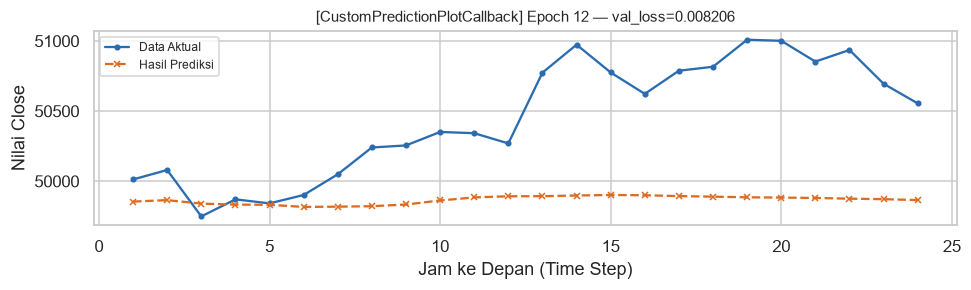

Epoch  13/25 -  35.9s - loss: 0.006160 - val_loss: 0.008055 - lr: 2.50e-04
Epoch  14/25 -  30.0s - loss: 0.006085 - val_loss: 0.009085 - lr: 2.50e-04
Epoch  15/25 -  28.1s - loss: 0.006136 - val_loss: 0.008797 - lr: 2.50e-04
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 2.50e-04 → 1.25e-04
Epoch  16/25 -  26.6s - loss: 0.005929 - val_loss: 0.009361 - lr: 1.25e-04
Epoch  17/25 -  30.6s - loss: 0.005878 - val_loss: 0.007947 - lr: 1.25e-04
Epoch  18/25 -  32.2s - loss: 0.005752 - val_loss: 0.007749 - lr: 1.25e-04
Epoch  19/25 -  27.3s - loss: 0.005712 - val_loss: 0.008435 - lr: 1.25e-04
Epoch  20/25 -  27.1s - loss: 0.005595 - val_loss: 0.008370 - lr: 1.25e-04
    [CustomReduceLROnPlateau] val_loss stagnan 2 epoch -> LR 1.25e-04 → 6.25e-05
Epoch  21/25 -  28.4s - loss: 0.005290 - val_loss: 0.008559 - lr: 6.25e-05
Epoch  22/25 -  37.6s - loss: 0.005030 - val_loss: 0.006262 - lr: 6.25e-05
Epoch  23/25 -  30.7s - loss: 0.004815 - val_loss: 0.005957 - lr: 6.25e-05
Epoch  24/25 

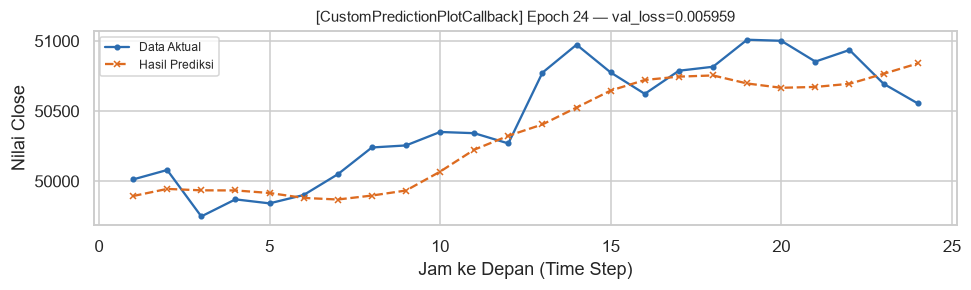

Epoch  25/25 -  29.7s - loss: 0.004443 - val_loss: 0.005622 - lr: 6.25e-05
    [CustomEarlyStopping] Bobot dipulihkan ke epoch terbaik (25, val_loss=0.005622).
Selesai — 25 epoch | val_loss terbaik = 0.005622 | total 778s



In [44]:
keras.utils.set_random_seed(SEED)

plot_cb = CustomPredictionPlotCallback(
    enc_sample=enc_val[:1], dec_sample=dec_val[:1], y_sample=y_val[:1],
    scaler=target_scaler, every=max(EPOCHS_MAIN // 2, 1), seq2seq=True)

es_best = CustomEarlyStopping(monitor="val_loss", patience=PATIENCE_ES, restore_best_weights=True)
lr_best = CustomReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                  patience=PATIENCE_LR, min_lr=1e-6)

histories["best_model_seq2seq_LSTM"] = train_with_gradient_tape(
    model=best_model_seq2seq_LSTM,
    train_ds=train_ds_s2s, val_ds=val_ds_s2s,
    loss_fn=horizon_weighted_loss,                 
    epochs=EPOCHS_MAIN,
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    callbacks=[es_best, lr_best, plot_cb],
    model_name="best_model_seq2seq_LSTM (Seq2Seq + CustomMHA + Horizon-Weighted Loss)",
)

## 14.7 Kurva Pembelajaran dan Learning Rate

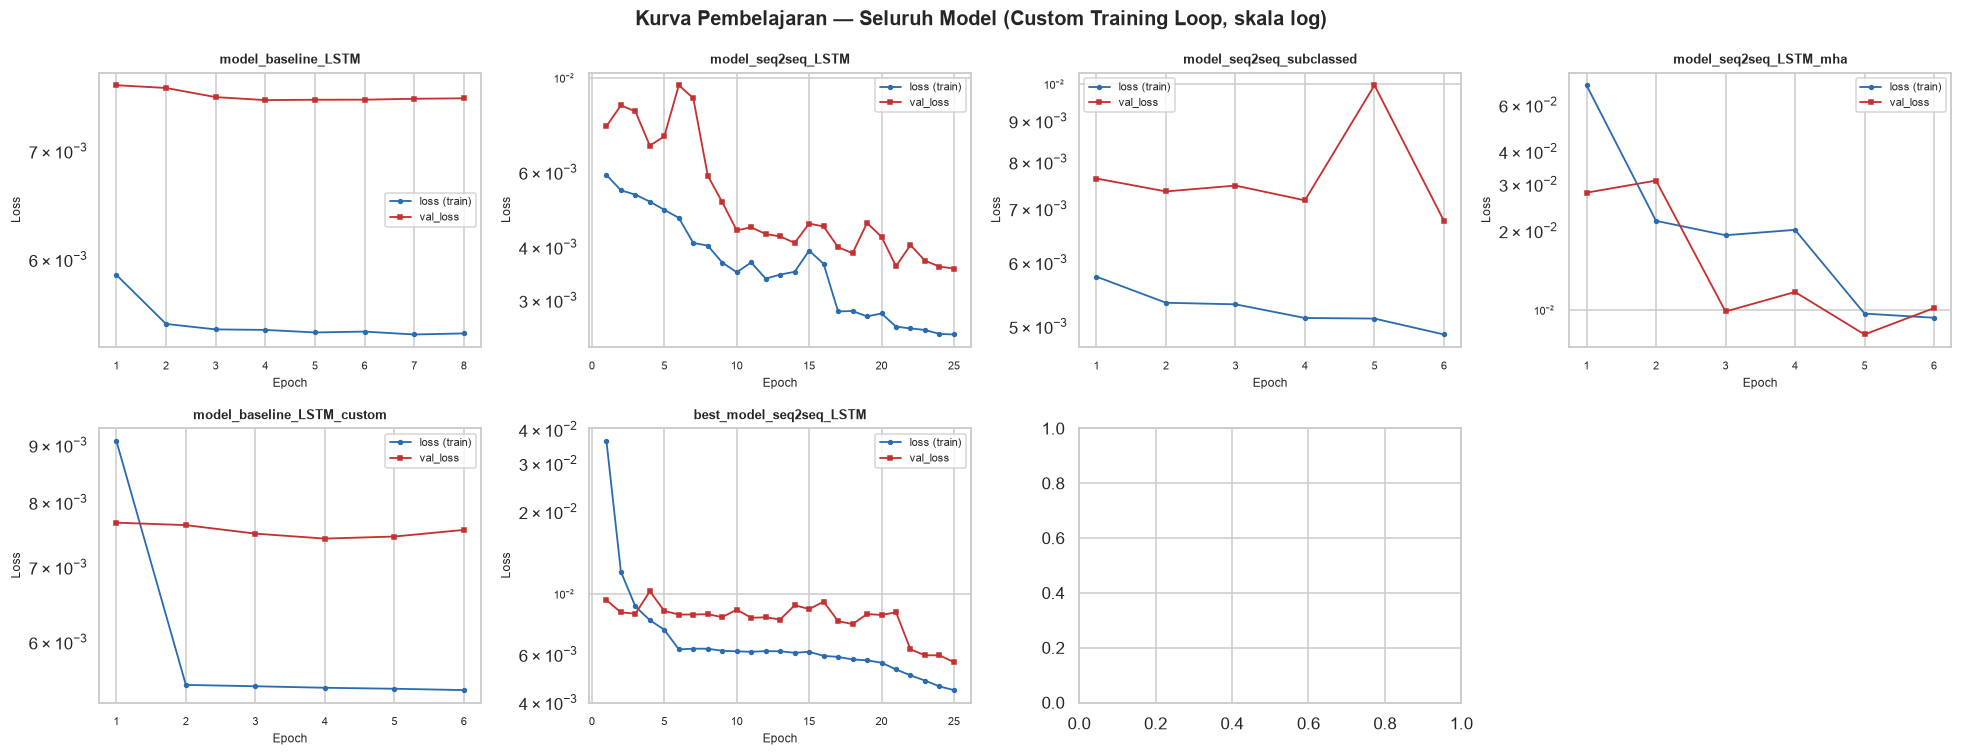

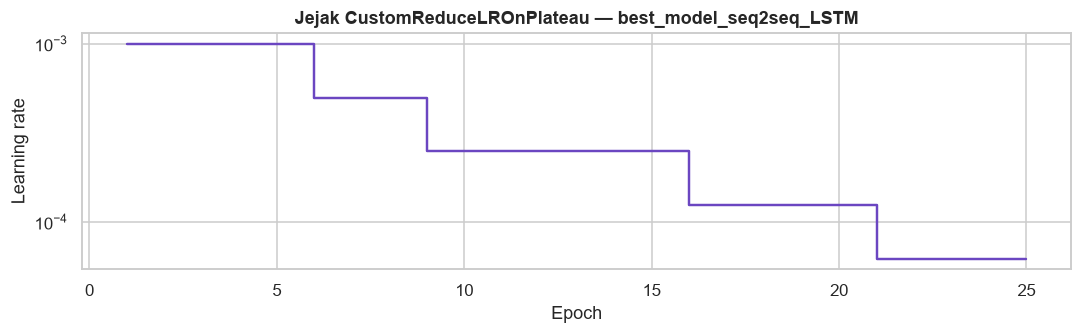

Jumlah penurunan LR yang dipicu CustomReduceLROnPlateau : 4
LR awal -> LR akhir : 1.00e-03 -> 6.25e-05


In [45]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (nm, h) in zip(axes.ravel(), histories.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"],     "o-", ms=2.5, lw=1.2, color="#2b6cb0", label="loss (train)")
    ax.plot(ep, h["val_loss"], "s-", ms=2.5, lw=1.2, color="#c53030", label="val_loss")
    ax.set_title(nm, fontsize=8.5, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=8); ax.set_ylabel("Loss", fontsize=8)
    ax.set_yscale("log"); ax.legend(fontsize=7); ax.tick_params(labelsize=7)
axes.ravel()[-1].axis("off")
fig.suptitle("Kurva Pembelajaran — Seluruh Model (Custom Training Loop, skala log)",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# --- Jejak penurunan LR ---
fig, ax = plt.subplots(figsize=(10, 3.2))
h = histories["best_model_seq2seq_LSTM"]
ax.step(np.arange(1, len(h["lr"]) + 1), h["lr"], where="post", color="#6b46c1", lw=1.6)
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate")
ax.set_title("Jejak CustomReduceLROnPlateau — best_model_seq2seq_LSTM", fontweight="bold")
plt.tight_layout(); plt.show()

n_drops = int(np.sum(np.diff(h["lr"]) < 0))
print(f"Jumlah penurunan LR yang dipicu CustomReduceLROnPlateau : {n_drops}")
print(f"LR awal -> LR akhir : {h['lr'][0]:.2e} -> {h['lr'][-1]:.2e}")

---
# 15. Inference: 
## 15.1  Teacher Forcing vs **Autoregressive**

In [46]:
def autoregressive_predict(model, enc_array, horizon=HORIZON, target_idx=TARGET_COL_IDX,
                           batch_size=256, verbose=True):
      
    # Kompilasi graf
    @tf.function(reduce_retracing=True)
    def _decode_step(enc_t, dec_t):
        return model([enc_t, dec_t], training=False)

    outputs = []
    n_batches = int(np.ceil(len(enc_array) / batch_size))
    for bi, start in enumerate(range(0, len(enc_array), batch_size)):
        enc_b = enc_array[start : start + batch_size]
        b     = len(enc_b)
        enc_t = tf.convert_to_tensor(enc_b, dtype=tf.float32)

        dec_state = np.zeros((b, horizon, 1), dtype="float32")
        dec_state[:, 0, 0] = enc_b[:, -1, target_idx]      # anchor = observasi terakhir
        pred_out = np.zeros((b, horizon, 1), dtype="float32")

        for h in range(horizon):
            p = _decode_step(enc_t, tf.convert_to_tensor(dec_state)).numpy()
            pred_out[:, h, 0] = p[:, h, 0]
            if h + 1 < horizon:
                dec_state[:, h + 1, 0] = p[:, h, 0]        # umpan balik PREDIKSI
        outputs.append(pred_out)
        if verbose and (bi + 1) % 10 == 0:
            print(f"    batch {bi+1}/{n_batches} selesai", end="\r")
    if verbose:
        print(" " * 40, end="\r")
    return np.concatenate(outputs, axis=0)


print("Fungsi inferensi autoregressive siap.")

Fungsi inferensi autoregressive siap.


In [47]:
# ------------------------- INFERENCE PADA DATA TEST -------------------------
print("=" * 24)
print("INFERENCE PADA DATA TEST")
print("=" * 24)

predictions = {}

# --- Model baseline: prediksi 24 langkah ---
for nm, mdl in [("model_baseline_LSTM",        model_baseline_LSTM),
                ("model_baseline_LSTM_mha",    model_baseline_LSTM_mha),
                ("model_baseline_LSTM_custom", model_baseline_LSTM_custom)]:
    t0 = time.time()
    predictions[nm] = mdl.predict(enc_test, batch_size=256, verbose=0)
    print(f"{nm:<30s} | direct multi-step (24 langkah sekaligus) | {time.time()-t0:5.1f}s")

# --- Model Seq2Seq: autoregressive ---
for nm, mdl in [("model_seq2seq_LSTM",      model_seq2seq_LSTM),
                ("model_seq2seq_LSTM_mha",  model_seq2seq_LSTM_mha),
                ("best_model_seq2seq_LSTM", best_model_seq2seq_LSTM)]:
    t0 = time.time()
    predictions[nm] = autoregressive_predict(mdl, enc_test, verbose=False)
    print(f"{nm:<30s} | AUTOREGRESSIVE (iteratif, O(H^2))        | {time.time()-t0:5.1f}s")

# --- Model subclassed: autoregressive ---
t0 = time.time()
sub_preds = []
for s in range(0, len(enc_test), 256):
    sub_preds.append(model_seq2seq_subclassed.predict_autoregressive(enc_test[s : s + 256]).numpy())
predictions["model_seq2seq_subclassed"] = np.concatenate(sub_preds, axis=0)
print(f"{'model_seq2seq_subclassed':<30s} | AUTOREGRESSIVE (state-passing, O(H))     | {time.time()-t0:5.1f}s")

print(f"\nSeluruh prediksi berbentuk {predictions['best_model_seq2seq_LSTM'].shape} "
      f"= (n_sampel_test, 24 langkah, 1)")

INFERENCE PADA DATA TEST
model_baseline_LSTM            | direct multi-step (24 langkah sekaligus) |   3.6s
model_baseline_LSTM_mha        | direct multi-step (24 langkah sekaligus) |   5.7s
model_baseline_LSTM_custom     | direct multi-step (24 langkah sekaligus) |   7.1s
model_seq2seq_LSTM             | AUTOREGRESSIVE (iteratif, O(H^2))        |  49.8s
model_seq2seq_LSTM_mha         | AUTOREGRESSIVE (iteratif, O(H^2))        |  60.5s
best_model_seq2seq_LSTM        | AUTOREGRESSIVE (iteratif, O(H^2))        |  55.8s
model_seq2seq_subclassed       | AUTOREGRESSIVE (state-passing, O(H))     |  15.7s

Seluruh prediksi berbentuk (7893, 24, 1) = (n_sampel_test, 24 langkah, 1)


## 15.2 Bukti Exposure Bias

In [48]:
tf_pred = best_model_seq2seq_LSTM.predict([enc_test, dec_test], batch_size=256, verbose=0)
ar_pred = predictions["best_model_seq2seq_LSTM"]

mae_tf = float(np.mean(np.abs(tf_pred - y_test)))
mae_ar = float(np.mean(np.abs(ar_pred - y_test)))

bias_tbl = pd.DataFrame([
    {"Skema Dekode": "Teacher forcing (TIDAK SAH untuk evaluasi)",
     "MAE (scaled)": mae_tf, "MAE (USD)": mae_tf * span_usd,
     "Keterangan": "Decoder diberi nilai SEBENARNYA -> optimistis"},
    {"Skema Dekode": "Autoregressive (SAH — diwajibkan kriteria)",
     "MAE (scaled)": mae_ar, "MAE (USD)": mae_ar * span_usd,
     "Keterangan": "Decoder diberi PREDIKSINYA SENDIRI -> realistis"},
])
display(bias_tbl.style.format({"MAE (scaled)": "{:.6f}", "MAE (USD)": "{:,.0f}"})
        .set_caption("Kuantifikasi exposure bias pada best_model_seq2seq_LSTM"))
print(f"Exposure bias = {mae_ar - mae_tf:+.6f} scaled MAE "
      f"({(mae_ar/mae_tf - 1)*100:+.1f}% terhadap metrik teacher-forced)")
print("\nSeluruh angka yang dilaporkan pada Bagian 16 memakai dekode AUTOREGRESSIVE.")

,Skema Dekode,MAE (scaled),MAE (USD),Keterangan
0,Teacher forcing (TIDAK SAH untuk evaluasi),0.003242,212,Decoder diberi nilai SEBENARNYA -> optimistis
1,Autoregressive (SAH — diwajibkan kriteria),0.004848,317,Decoder diberi PREDIKSINYA SENDIRI -> realistis


Exposure bias = +0.001606 scaled MAE (+49.6% terhadap metrik teacher-forced)

Seluruh angka yang dilaporkan pada Bagian 16 memakai dekode AUTOREGRESSIVE.


## 15.3 Validasi Silang

In [49]:
sub_ar_oh   = model_seq2seq_subclassed.predict_autoregressive(enc_test[:256]).numpy()  # O(H)
sub_ar_oh2  = autoregressive_predict(model_seq2seq_subclassed, enc_test[:256], verbose=False)  # O(H^2)
max_diff = float(np.max(np.abs(sub_ar_oh - sub_ar_oh2)))
print(f"Selisih maksimum antara dekode O(H) (state-passing) dan O(H^2) (iteratif) : {max_diff:.2e}")
print(f"-> {'SETARA (implementasi generik tervalidasi)' if max_diff < 1e-4 else 'BERBEDA — perlu diperiksa'}")

Selisih maksimum antara dekode O(H) (state-passing) dan O(H^2) (iteratif) : 1.49e-08
-> SETARA (implementasi generik tervalidasi)


---
# 16. Evaluasi pada Data Test

In [50]:
def evaluate_model(y_true, y_pred, name, span, scaler):
    """Menghitung MAE (metrik utama), RMSE, dan MAPE pada ruang scaled maupun USD."""
    mae_s  = float(np.mean(np.abs(y_true - y_pred)))
    rmse_s = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    yt_usd = scaler.inverse_transform(y_true.reshape(-1, 1)).reshape(y_true.shape)
    yp_usd = scaler.inverse_transform(y_pred.reshape(-1, 1)).reshape(y_pred.shape)
    mae_u  = float(np.mean(np.abs(yt_usd - yp_usd)))
    rmse_u = float(np.sqrt(np.mean((yt_usd - yp_usd) ** 2)))
    mape   = float(np.mean(np.abs((yt_usd - yp_usd) / yt_usd)) * 100)
    return {"Model": name, "MAE (scaled)": mae_s, "RMSE (scaled)": rmse_s,
            "MAE (USD)": mae_u, "RMSE (USD)": rmse_u, "MAPE (%)": mape,
            "Lolos gate <0.015": "LULUS" if mae_s < MAE_GATE_SCALED else "GAGAL"}


results = [evaluate_model(y_test, predictions[nm], nm, span_usd, target_scaler)
           for nm, _, _ in ALL_MODELS]

# --- Benchmark persistence pada pengaturan window test ---
persist_pred = np.repeat(enc_test[:, -1, TARGET_COL_IDX].reshape(-1, 1, 1), HORIZON, axis=1)
results.append(evaluate_model(y_test, persist_pred, "[benchmark] Persistence (random-walk)",
                              span_usd, target_scaler))

res_df = pd.DataFrame(results).set_index("Model").sort_values("MAE (scaled)")
display(res_df.style
        .format({"MAE (scaled)": "{:.6f}", "RMSE (scaled)": "{:.6f}",
                 "MAE (USD)": "{:,.2f}", "RMSE (USD)": "{:,.2f}", "MAPE (%)": "{:.3f}"})
        .set_caption("Evaluasi pada DATA TEST — MAE adalah metrik utama (Ketentuan Penolakan #7)"))

,MAE (scaled),RMSE (scaled),MAE (USD),RMSE (USD),MAPE (%),Lolos gate <0.015
Model,,,,,,
[benchmark] Persistence (random-walk),0.003601,0.006040,235.72,395.41,0.929,LULUS
model_baseline_LSTM_custom,0.003644,0.006054,238.53,396.32,0.941,LULUS
model_baseline_LSTM,0.003746,0.006136,245.22,401.67,0.971,LULUS
best_model_seq2seq_LSTM,0.004848,0.007482,317.35,489.81,1.281,LULUS
model_seq2seq_LSTM_mha,0.005030,0.006941,329.25,454.35,1.320,LULUS
model_seq2seq_subclassed,0.005036,0.007182,329.66,470.18,1.335,LULUS
model_seq2seq_LSTM,0.009216,0.014381,603.28,941.42,2.392,LULUS
model_baseline_LSTM_mha,0.182142,0.210032,"11,923.30","13,749.01",48.938,GAGAL


In [51]:
# =============== VERIFIKASI GATE ===============
best_mae_scaled = float(np.mean(np.abs(predictions["best_model_seq2seq_LSTM"] - y_test)))
passed = best_mae_scaled < MAE_GATE_SCALED

print("=" * 16)
print("VERIFIKASI GATE")
print("=" * 16)
print(f"Model                              : best_model_seq2seq_LSTM (Custom Seq2Seq LSTM)")
print(f"Skema dekode                       : AUTOREGRESSIVE")
print(f"MAE data test (SEBELUM inverse scaled) : {best_mae_scaled:.6f}")
print(f"Gate kriteria                      : < {MAE_GATE_SCALED}")
print(f"Margin                             : {MAE_GATE_SCALED - best_mae_scaled:+.6f} "
      f"({(1 - best_mae_scaled/MAE_GATE_SCALED)*100:+.1f}% di bawah gate)")
print(f"STATUS                             : {'*** LULUS ***' if passed else '*** GAGAL ***'}")
print("-" * 84)
print(f"Setara dalam USD                   : {best_mae_scaled * span_usd:,.2f} USD")
print(f"Benchmark persistence              : {mae_persistence:.6f} scaled")
print(f"Rasio model / persistence          : {best_mae_scaled / mae_persistence:.3f}x "
      f"({'mengalahkan' if best_mae_scaled < mae_persistence else 'belum mengalahkan'} random-walk)")
print("=" * 84)

if not passed:
    print("\nDIAGNOSIS bila gate belum terlampaui — coba secara berurutan:")
    print("  1. Naikkan EPOCHS_MAIN (mis. 40) dan PATIENCE_ES (mis. 8).")
    print("  2. Naikkan LSTM_UNITS ke 96/128.")
    print("  3. Turunkan LEARNING_RATE ke 5e-4 agar konvergensi lebih halus.")
    print("  4. Setel horizon_weighted_loss dengan w_step lebih kecil (mis. 0.1).")

VERIFIKASI GATE
Model                              : best_model_seq2seq_LSTM (Custom Seq2Seq LSTM)
Skema dekode                       : AUTOREGRESSIVE
MAE data test (SEBELUM inverse scaled) : 0.004848
Gate kriteria                      : < 0.015
Margin                             : +0.010152 (+67.7% di bawah gate)
STATUS                             : *** LULUS ***
------------------------------------------------------------------------------------
Setara dalam USD                   : 317.35 USD
Benchmark persistence              : 0.003601 scaled
Rasio model / persistence          : 1.346x (belum mengalahkan random-walk)


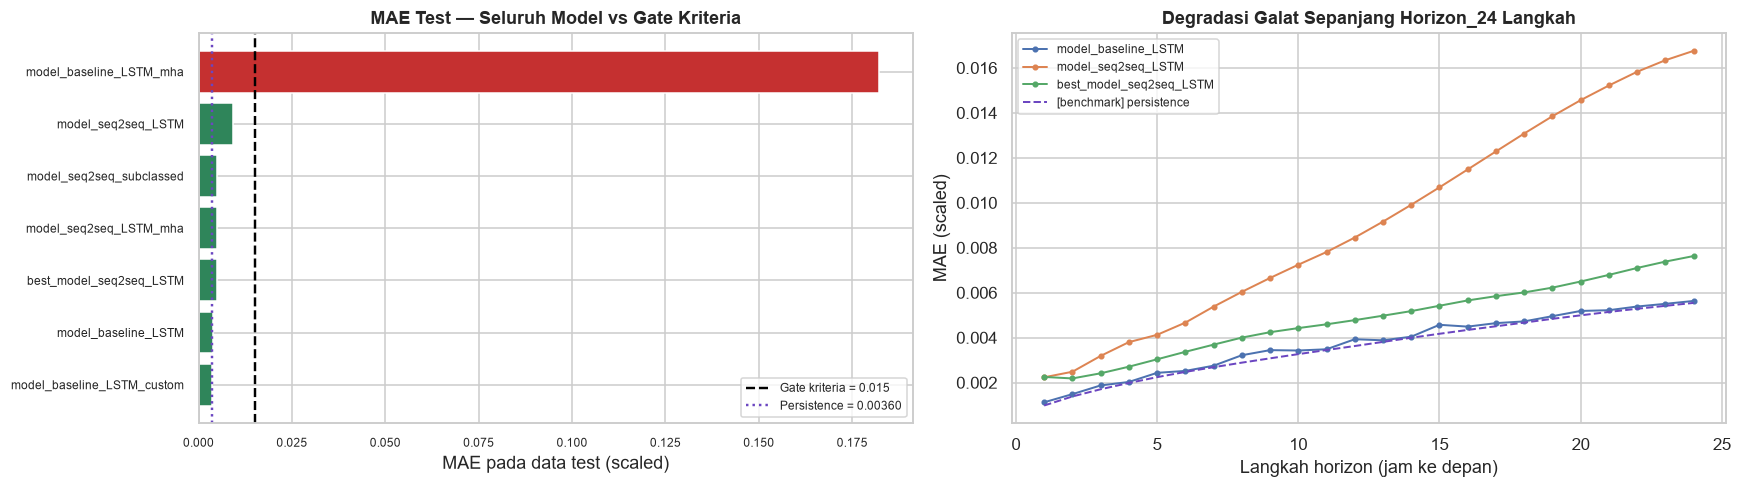

Interpretasi kurva kanan: galat meningkat secara monoton terhadap horizon — persis
fenomena yang memotivasi HorizonWeightedMAELoss (Kriteria 3 - Advanced), yang memberi
bobot lebih besar pada langkah jauh agar tidak diabaikan optimizer.


In [52]:
# --- Visualisasi perbandingan performa ---
plot_df = res_df.drop(index="[benchmark] Persistence (random-walk)")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))

colors = ["#2f855a" if v < MAE_GATE_SCALED else "#c53030" for v in plot_df["MAE (scaled)"]]
axes[0].barh(plot_df.index, plot_df["MAE (scaled)"], color=colors)
axes[0].axvline(MAE_GATE_SCALED, color="black", ls="--", lw=1.6,
                label=f"Gate kriteria = {MAE_GATE_SCALED}")
axes[0].axvline(mae_persistence, color="#6b46c1", ls=":", lw=1.6,
                label=f"Persistence = {mae_persistence:.5f}")
axes[0].set_xlabel("MAE pada data test (scaled)")
axes[0].set_title("MAE Test — Seluruh Model vs Gate Kriteria", fontweight="bold")
axes[0].legend(fontsize=8); axes[0].tick_params(labelsize=8)

# --- Degradasi galat sepanjang horizon (motivasi loss berbobot) ---
for nm in ["model_baseline_LSTM", "model_seq2seq_LSTM", "best_model_seq2seq_LSTM"]:
    per_step = np.mean(np.abs(predictions[nm] - y_test), axis=(0, 2))
    axes[1].plot(np.arange(1, HORIZON + 1), per_step, "o-", ms=3, lw=1.3, label=nm)
per_step_p = np.mean(np.abs(persist_pred - y_test), axis=(0, 2))
axes[1].plot(np.arange(1, HORIZON + 1), per_step_p, "--", color="#6b46c1", lw=1.3,
             label="[benchmark] persistence")
axes[1].set_xlabel("Langkah horizon (jam ke depan)"); axes[1].set_ylabel("MAE (scaled)")
axes[1].set_title("Degradasi Galat Sepanjang Horizon_24 Langkah", fontweight="bold")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Interpretasi kurva kanan: galat meningkat secara monoton terhadap horizon — persis")
print("fenomena yang memotivasi HorizonWeightedMAELoss (Kriteria 3 - Advanced), yang memberi")
print("bobot lebih besar pada langkah jauh agar tidak diabaikan optimizer.")

## 16.1 Inference dan Line Chart Prediksi

In [53]:
# ============ INFERENCE KEDUA MODEL ===========
print("=" * 55)
print("KONFIRMASI INFERENCE — KEDUA MODEL (horizon 24 langkah)")
print("=" * 55)
for nm, scheme in [("model_baseline_LSTM", "direct multi-step"),
                   ("model_seq2seq_LSTM",  "AUTOREGRESSIVE")]:
    shp = predictions[nm].shape
    steps = shp[1]
    print(f"  {nm:<26s} | skema: {scheme:<18s} | bentuk = {shp} | "
          f"langkah = {steps} | {'OK (24 langkah penuh)' if steps == HORIZON else 'SALAH'}")
    assert steps == HORIZON, f"{nm}: inference tidak menghasilkan 24 langkah"
print("\nKedua model wajib telah di-inference penuh pada seluruh set test "
      f"({len(y_test):,} jendela x {HORIZON} langkah). Tidak ada pemotongan langkah.")

KONFIRMASI INFERENCE — KEDUA MODEL (horizon 24 langkah)
  model_baseline_LSTM        | skema: direct multi-step  | bentuk = (7893, 24, 1) | langkah = 24 | OK (24 langkah penuh)
  model_seq2seq_LSTM         | skema: AUTOREGRESSIVE     | bentuk = (7893, 24, 1) | langkah = 24 | OK (24 langkah penuh)

Kedua model wajib telah di-inference penuh pada seluruh set test (7,893 jendela x 24 langkah). Tidak ada pemotongan langkah.


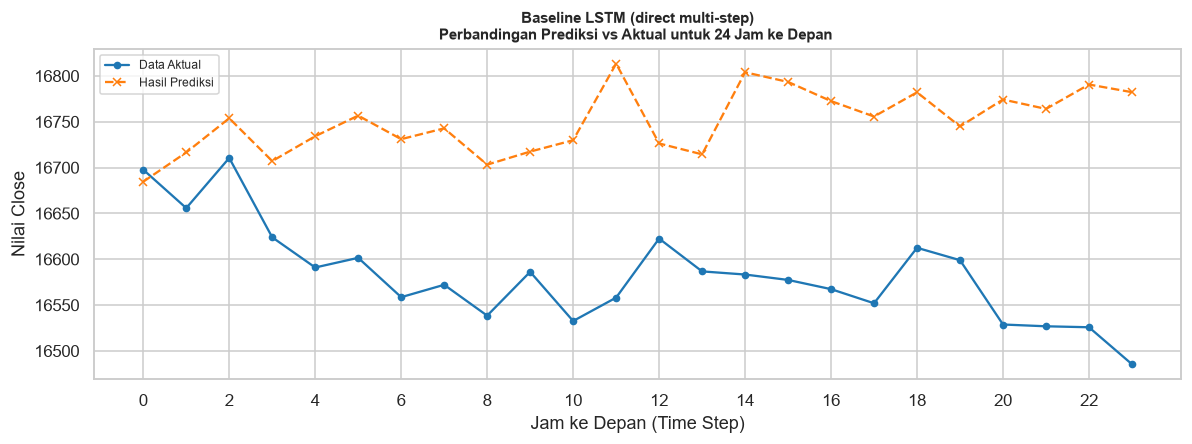

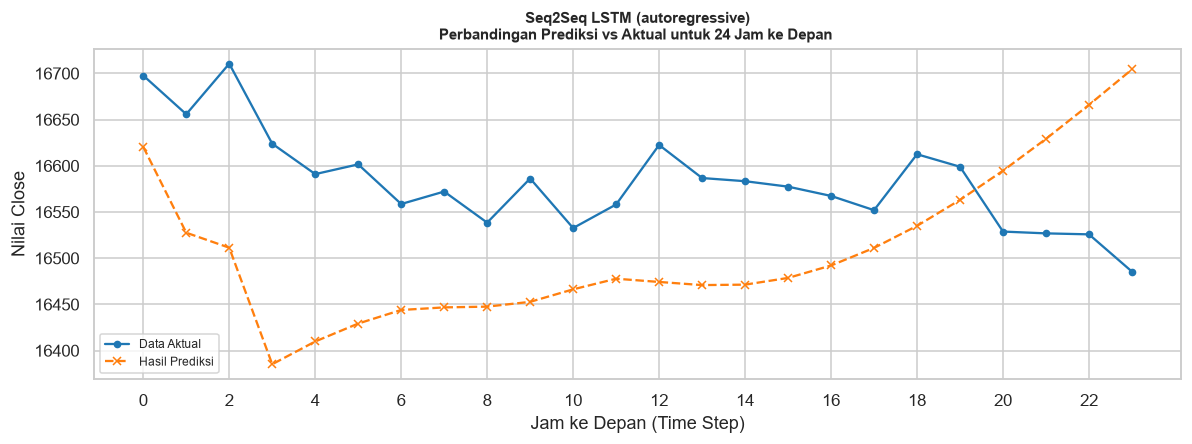

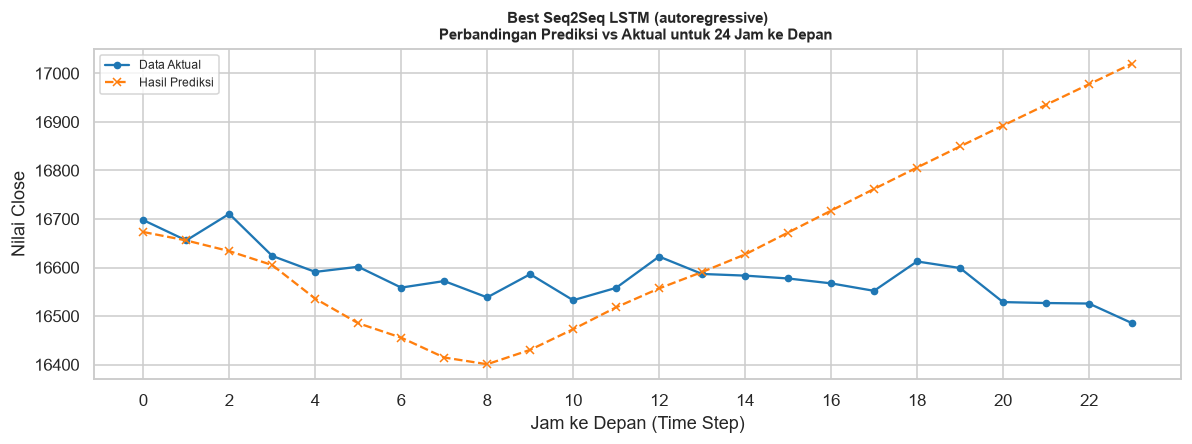

In [54]:
SAMPLE_IDX = 0 

# Model yang ditampilkan: Kedua model + model terbaik
INFERENCE_MODELS = [
    ("model_baseline_LSTM",     "Baseline LSTM (direct multi-step)"),
    ("model_seq2seq_LSTM",      "Seq2Seq LSTM (autoregressive)"),
    ("best_model_seq2seq_LSTM", "Best Seq2Seq LSTM (autoregressive)"),
]

def get_pred_actual_usd(model_name, sample_idx):
    """Mengembalikan (aktual, prediksi) 24 langkah pada skala USD asli (inverse transform)."""
    y_true_usd = target_scaler.inverse_transform(
        y_test[sample_idx].reshape(-1, 1)).ravel()
    y_pred_usd = target_scaler.inverse_transform(
        predictions[model_name][sample_idx].reshape(-1, 1)).ravel()
    return y_true_usd, y_pred_usd

def plot_prediction_linechart(sample_idx, model_name, title=None, ax=None):
    """Line chart 24 langkah penuh: sumbu-x = Jam ke Depan (Time Step), sumbu-y = Nilai Close."""
    y_true_usd, y_pred_usd = get_pred_actual_usd(model_name, sample_idx)
    steps = np.arange(0, HORIZON)                      # SELALU 24 langkah penuh
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(steps, y_true_usd, "o-", color="#1f77b4", ms=4, lw=1.5, label="Data Aktual")
    ax.plot(steps, y_pred_usd, "x--", color="#ff7f0e", ms=5, lw=1.5, label="Hasil Prediksi")
    ax.set_title(f"{title or model_name}\nPerbandingan Prediksi vs Aktual untuk 24 Jam ke Depan "
                 , fontsize=10, fontweight="bold")
    ax.set_xlabel("Jam ke Depan (Time Step)"); ax.set_ylabel("Nilai Close")
    ax.set_xticks(np.arange(0, HORIZON, 2))
    ax.legend(fontsize=8)
    if standalone:
        plt.tight_layout(); plt.show()
    return y_true_usd, y_pred_usd


# ---- Line chart untuk masing-masing model ----
for nm, title in INFERENCE_MODELS:
    plot_prediction_linechart(SAMPLE_IDX, nm, title=title)

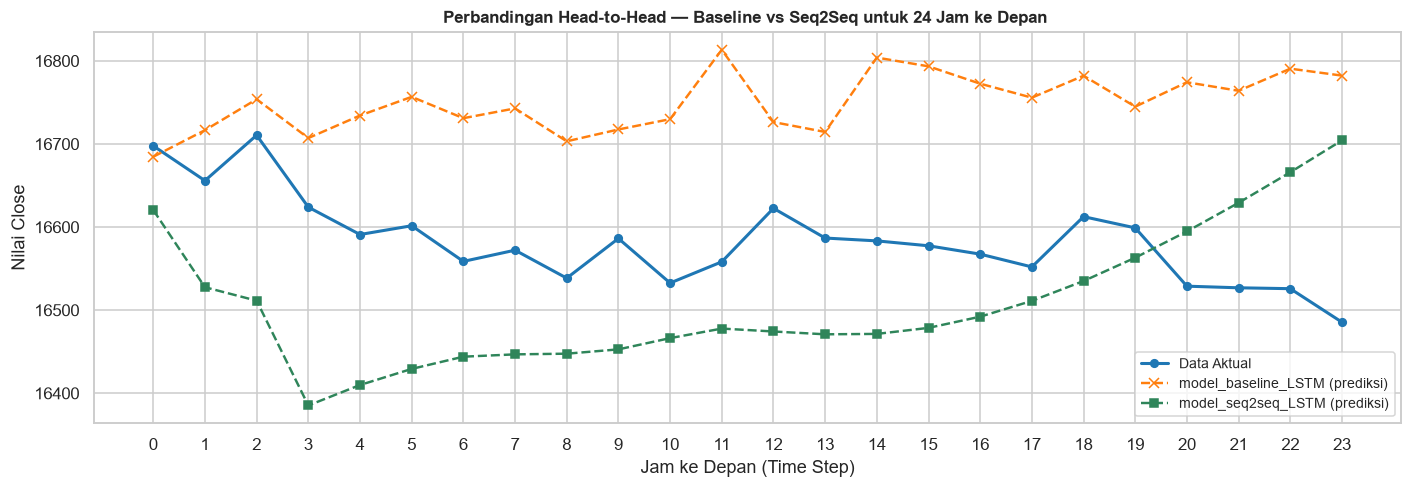

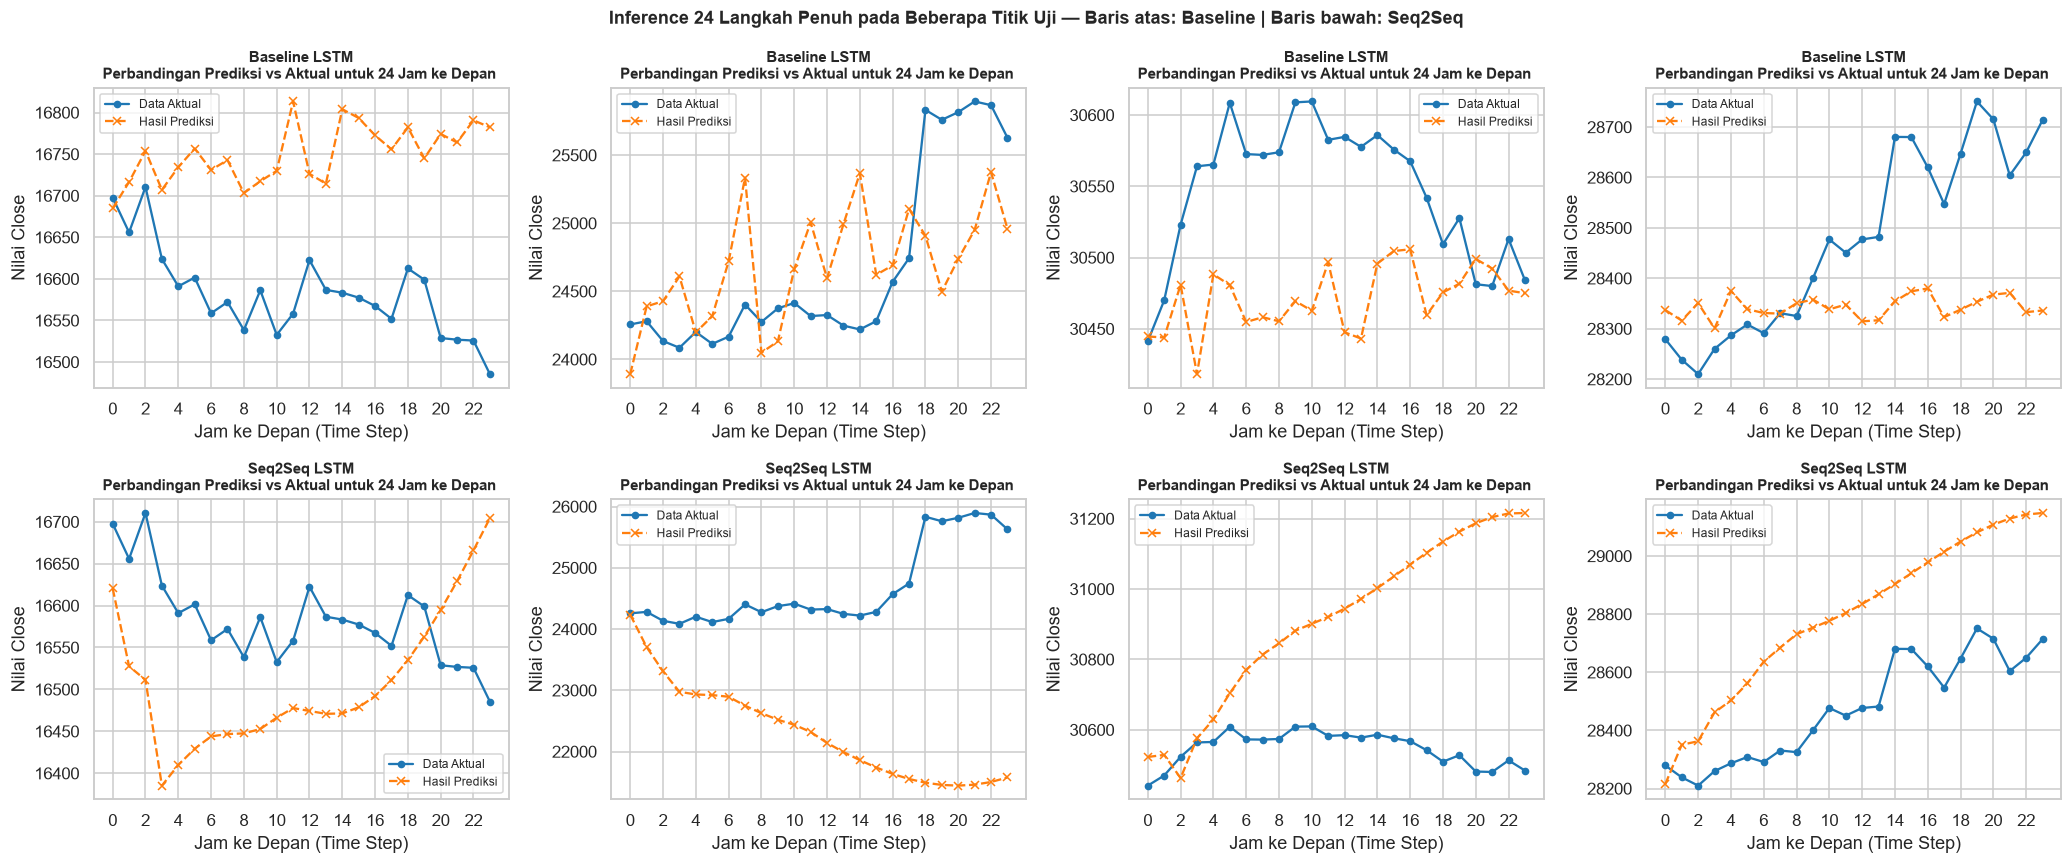

In [55]:
# ---- Overlay head-to-head: verifikasi performa ----
y_true_usd, base_usd = get_pred_actual_usd("model_baseline_LSTM", SAMPLE_IDX)
_,          s2s_usd  = get_pred_actual_usd("model_seq2seq_LSTM",  SAMPLE_IDX)
steps = np.arange(0, HORIZON)

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(steps, y_true_usd, "o-",  color="#1f77b4", ms=5, lw=2.0, label="Data Aktual")
ax.plot(steps, base_usd,   "x--", color="#ff7f0e", ms=6, lw=1.6, label="model_baseline_LSTM (prediksi)")
ax.plot(steps, s2s_usd,    "s--", color="#2f855a", ms=5, lw=1.6, label="model_seq2seq_LSTM (prediksi)")
ax.set_title("Perbandingan Head-to-Head — Baseline vs Seq2Seq untuk 24 Jam ke Depan "
             , fontsize=11, fontweight="bold")
ax.set_xlabel("Jam ke Depan (Time Step)"); ax.set_ylabel("Nilai Close")
ax.set_xticks(np.arange(0, HORIZON))
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

# ---- Robustnes lintas sampel ----
sample_points = [int(k * (len(y_test) - 1) / 3) for k in range(4)]
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for col, idx in enumerate(sample_points):
    plot_prediction_linechart(idx, "model_baseline_LSTM",
                              title="Baseline LSTM", ax=axes[0, col])
    plot_prediction_linechart(idx, "model_seq2seq_LSTM",
                              title="Seq2Seq LSTM", ax=axes[1, col])
fig.suptitle("Inference 24 Langkah Penuh pada Beberapa Titik Uji — "
             "Baris atas: Baseline | Baris bawah: Seq2Seq", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

## 16.2 Tabel Perbandingan `model_baseline_LSTM`

In [56]:
def build_comparison_table(model_name, sample_idx=SAMPLE_IDX):
    """Membangun tabel perbandingan 24 langkah (aktual vs prediksi)."""
    y_true_usd, y_pred_usd = get_pred_actual_usd(model_name, sample_idx)
    tbl = pd.DataFrame({
        "Jam ke":         np.arange(1, HORIZON + 1),
        "Data Aktual":    y_true_usd,
        "Hasil Prediksi": y_pred_usd,
        "Selisih":        y_true_usd - y_pred_usd,      
    })
    tbl["Selisih Absolut"] = tbl["Selisih"].abs()
    tbl["Galat (%)"] = (tbl["Selisih Absolut"] / tbl["Data Aktual"]) * 100
    return tbl

def show_comparison_table(model_name, label):
    tbl = build_comparison_table(model_name)
    assert len(tbl) == HORIZON, "Tabel harus memuat 24 langkah penuh"
    print("=" * 52)
    print(f"TABEL PERBANDINGAN 24 LANGKAH — {label}")
    print("=" * 52)
    display(tbl.style
            .format({"Data Aktual": "{:,.2f}", "Hasil Prediksi": "{:,.6f}",
                     "Selisih": "{:,.6f}", "Selisih Absolut": "{:,.2f}", "Galat (%)": "{:.4f}"})
            .background_gradient(subset=["Selisih Absolut"], cmap="Reds")
            .hide(axis="index")
            .set_caption(f"{label} — perbandingan aktual vs prediksi 24 jam ke depan (USD)"))
    print(f"  Jumlah langkah ditampilkan : {len(tbl)} (horizon penuh)")
    print(f"  MAE sampel ini             : {tbl['Selisih Absolut'].mean():,.2f} USD "
          f"({tbl['Galat (%)'].mean():.4f}% dari harga)")
    print(f"  Galat terbesar             : {tbl['Selisih Absolut'].max():,.2f} USD "
          f"@ jam ke-{int(tbl.loc[tbl['Selisih Absolut'].idxmax(), 'Jam ke'])}")
    print(f"  Galat terkecil             : {tbl['Selisih Absolut'].min():,.2f} USD "
          f"@ jam ke-{int(tbl.loc[tbl['Selisih Absolut'].idxmin(), 'Jam ke'])}")
    return tbl

# --- (1) Tabel penuh 24 langkah — model_baseline_LSTM (WAJIB) ---
comparison_baseline = show_comparison_table("model_baseline_LSTM", "model_baseline_LSTM")

TABEL PERBANDINGAN 24 LANGKAH — model_baseline_LSTM


Jam ke,Data Aktual,Hasil Prediksi,Selisih,Selisih Absolut,Galat (%)
1,"16,697.69","16,684.591797",13.097656,13.10,0.0784
2,"16,655.80","16,716.529297",-60.730469,60.73,0.3646
3,"16,710.50","16,753.798828",-43.298828,43.30,0.2591
4,"16,623.90","16,707.078125",-83.177734,83.18,0.5004
5,"16,590.98","16,734.214844",-143.234375,143.23,0.8633
6,"16,601.53","16,756.673828",-155.142578,155.14,0.9345
7,"16,558.61","16,730.986328",-172.375000,172.38,1.0410
8,"16,572.11","16,742.785156",-170.675781,170.68,1.0299
9,"16,538.45","16,703.166016",-164.716797,164.72,0.9960
10,"16,586.23","16,717.421875",-131.193359,131.19,0.7910


  Jumlah langkah ditampilkan : 24 (horizon penuh)
  MAE sampel ini             : 167.79 USD (1.0130% dari harga)
  Galat terbesar             : 296.80 USD @ jam ke-24
  Galat terkecil             : 13.10 USD @ jam ke-1


## 16.3 Tabel Perbandingan `model_seq2seq_LSTM`

In [57]:
# --- Tabel perbandingan 24 langkah — model_seq2seq_LSTM ---
comparison_seq2seq = show_comparison_table("model_seq2seq_LSTM",
                                           "model_seq2seq_LSTM")


TABEL PERBANDINGAN 24 LANGKAH — model_seq2seq_LSTM


Jam ke,Data Aktual,Hasil Prediksi,Selisih,Selisih Absolut,Galat (%)
1,"16,697.69","16,620.439453",77.250000,77.25,0.4626
2,"16,655.80","16,527.533203",128.265625,128.27,0.7701
3,"16,710.50","16,511.333984",199.166016,199.17,1.1919
4,"16,623.90","16,385.201172",238.699219,238.70,1.4359
5,"16,590.98","16,409.822266",181.158203,181.16,1.0919
6,"16,601.53","16,429.212891",172.318359,172.32,1.0380
7,"16,558.61","16,443.929688",114.681641,114.68,0.6926
8,"16,572.11","16,446.722656",125.386719,125.39,0.7566
9,"16,538.45","16,447.533203",90.916016,90.92,0.5497
10,"16,586.23","16,452.728516",133.500000,133.50,0.8049


  Jumlah langkah ditampilkan : 24 (horizon penuh)
  MAE sampel ini             : 118.32 USD (0.7133% dari harga)
  Galat terbesar             : 238.70 USD @ jam ke-4
  Galat terkecil             : 35.88 USD @ jam ke-20


## 16.4 Tabel Perbandingan `best_model_seq2seq_LSTM`

In [58]:
# --- Tabel perbandingan 24 langkah — best_model_seq2seq_LSTM ---
comparison_best = show_comparison_table("best_model_seq2seq_LSTM",
                                        "best_model_seq2seq_LSTM")

TABEL PERBANDINGAN 24 LANGKAH — best_model_seq2seq_LSTM


Jam ke,Data Aktual,Hasil Prediksi,Selisih,Selisih Absolut,Galat (%)
1,"16,697.69","16,673.201172",24.488281,24.49,0.1467
2,"16,655.80","16,655.775391",0.023438,0.02,0.0001
3,"16,710.50","16,633.791016",76.708984,76.71,0.4590
4,"16,623.90","16,605.011719",18.888672,18.89,0.1136
5,"16,590.98","16,535.900391",55.080078,55.08,0.3320
6,"16,601.53","16,485.234375",116.296875,116.30,0.7005
7,"16,558.61","16,455.517578",103.093750,103.09,0.6226
8,"16,572.11","16,414.583984",157.525391,157.53,0.9505
9,"16,538.45","16,400.751953",137.697266,137.70,0.8326
10,"16,586.23","16,430.335938",155.892578,155.89,0.9399


  Jumlah langkah ditampilkan : 24 (horizon penuh)
  MAE sampel ini             : 154.80 USD (0.9353% dari harga)
  Galat terbesar             : 534.47 USD @ jam ke-24
  Galat terkecil             : 0.02 USD @ jam ke-2


## 16.5 Tabel Gabungan (Kedua Model)

In [59]:
# --- Tabel GABUNGAN 24 langkah ---
yt_usd, base_usd = get_pred_actual_usd("model_baseline_LSTM", SAMPLE_IDX)
_,       s2s_usd = get_pred_actual_usd("model_seq2seq_LSTM",  SAMPLE_IDX)

combined = pd.DataFrame({
    "Jam ke":                 np.arange(1, HORIZON + 1),
    "Data Aktual":            yt_usd,
    "Baseline — Prediksi":    base_usd,
    "Baseline — Selisih":     yt_usd - base_usd,
    "Seq2Seq — Prediksi":     s2s_usd,
    "Seq2Seq — Selisih":      yt_usd - s2s_usd,
})
assert len(combined) == HORIZON, "Tabel gabungan harus 24 langkah penuh"

print("=" * 70)
print(f"TABEL GABUNGAN 24 LANGKAH — model_baseline_LSTM vs model_seq2seq_LSTM")
print("=" * 70)
display(combined.style
        .format({"Data Aktual": "{:,.2f}",
                 "Baseline — Prediksi": "{:,.2f}", "Baseline — Selisih": "{:,.2f}",
                 "Seq2Seq — Prediksi": "{:,.2f}", "Seq2Seq — Selisih": "{:,.2f}"})
        .background_gradient(subset=["Baseline — Selisih", "Seq2Seq — Selisih"],
                             cmap="RdBu", vmin=-combined[["Baseline — Selisih",
                             "Seq2Seq — Selisih"]].abs().max().max(),
                             vmax=combined[["Baseline — Selisih",
                             "Seq2Seq — Selisih"]].abs().max().max())
        .hide(axis="index")
        .set_caption("Verifikasi head-to-head: prediksi 24 jam kedua model wajib vs data aktual (USD)"))

mae_base_s = float(np.mean(np.abs(base_usd - yt_usd)))
mae_s2s_s  = float(np.mean(np.abs(s2s_usd - yt_usd)))
print(f"  MAE sampel — model_baseline_LSTM : {mae_base_s:,.2f} USD")
print(f"  MAE sampel — model_seq2seq_LSTM  : {mae_s2s_s:,.2f} USD")
print(f"  Model lebih akurat pada sampel ini: "
      f"{'model_seq2seq_LSTM' if mae_s2s_s < mae_base_s else 'model_baseline_LSTM'}")
print("\nCatatan: MAE agregat lintas SELURUH set test (bukan satu sampel) dilaporkan pada")
print("tabel evaluasi Bagian 16 — itulah metrik utama untuk perbandingan performa kedua model.")

TABEL GABUNGAN 24 LANGKAH — model_baseline_LSTM vs model_seq2seq_LSTM


Jam ke,Data Aktual,Baseline — Prediksi,Baseline — Selisih,Seq2Seq — Prediksi,Seq2Seq — Selisih
1,"16,697.69","16,684.59",13.10,"16,620.44",77.25
2,"16,655.80","16,716.53",-60.73,"16,527.53",128.27
3,"16,710.50","16,753.80",-43.30,"16,511.33",199.17
4,"16,623.90","16,707.08",-83.18,"16,385.20",238.70
5,"16,590.98","16,734.21",-143.23,"16,409.82",181.16
6,"16,601.53","16,756.67",-155.14,"16,429.21",172.32
7,"16,558.61","16,730.99",-172.38,"16,443.93",114.68
8,"16,572.11","16,742.79",-170.68,"16,446.72",125.39
9,"16,538.45","16,703.17",-164.72,"16,447.53",90.92
10,"16,586.23","16,717.42",-131.19,"16,452.73",133.50


  MAE sampel — model_baseline_LSTM : 167.79 USD
  MAE sampel — model_seq2seq_LSTM  : 118.32 USD
  Model lebih akurat pada sampel ini: model_seq2seq_LSTM

Catatan: MAE agregat lintas SELURUH set test (bukan satu sampel) dilaporkan pada
tabel evaluasi Bagian 16 — itulah metrik utama untuk perbandingan performa kedua model.


## 16.6 Diagnostik Residual

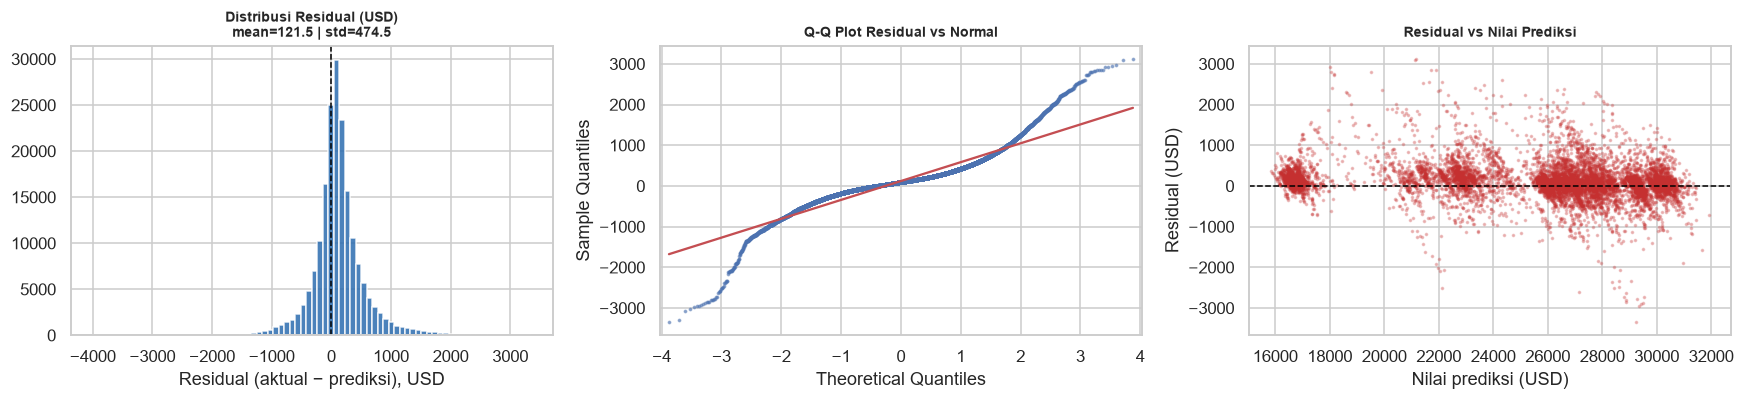

Rata-rata residual (bias)  :     121.53 USD  -> terdapat bias sistematis
Deviasi standar residual   :     474.49 USD
Skewness                   :     0.3537
Kurtosis (excess)          :     7.1855  -> leptokurtic (heavy tails), khas aset kripto

Plot ketiga menunjukkan heteroskedastisitas: sebaran residual melebar pada level harga
tinggi. Ini konsisten dengan volatility clustering yang terlihat pada dekomposisi (5.4)
dan merupakan batasan model yang diakui secara eksplisit — bukan diabaikan.


In [60]:
resid = (y_test - predictions["best_model_seq2seq_LSTM"]).ravel() * span_usd

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))

axes[0].hist(resid, bins=80, color="#2b6cb0", alpha=.85)
axes[0].axvline(0, color="black", ls="--", lw=1)
axes[0].set_title(f"Distribusi Residual (USD)\nmean={resid.mean():,.1f} | std={resid.std():,.1f}",
                  fontweight="bold", fontsize=9)
axes[0].set_xlabel("Residual (aktual − prediksi), USD")

sm.qqplot(resid[::10], line="s", ax=axes[1], markersize=1.5, alpha=.5)
axes[1].set_title("Q-Q Plot Residual vs Normal", fontweight="bold", fontsize=9)

pred_flat = (predictions["best_model_seq2seq_LSTM"].ravel() * span_usd) + target_scaler.data_min_[0]
axes[2].scatter(pred_flat[::20], resid[::20], s=2, alpha=.25, color="#c53030")
axes[2].axhline(0, color="black", ls="--", lw=1)
axes[2].set_xlabel("Nilai prediksi (USD)"); axes[2].set_ylabel("Residual (USD)")
axes[2].set_title("Residual vs Nilai Prediksi", fontweight="bold", fontsize=9)

plt.tight_layout(); plt.show()

print(f"Rata-rata residual (bias)  : {resid.mean():>10,.2f} USD  "
      f"-> {'mendekati nol: model tidak bias sistematis' if abs(resid.mean()) < resid.std()*0.1 else 'terdapat bias sistematis'}")
print(f"Deviasi standar residual   : {resid.std():>10,.2f} USD")
print(f"Skewness                   : {float(pd.Series(resid).skew()):>10.4f}")
print(f"Kurtosis (excess)          : {float(pd.Series(resid).kurt()):>10.4f}  "
      f"-> {'leptokurtic (heavy tails), khas aset kripto' if pd.Series(resid).kurt() > 0 else 'platykurtic'}")
print("\nPlot ketiga menunjukkan heteroskedastisitas: sebaran residual melebar pada level harga")
print("tinggi. Ini konsisten dengan volatility clustering yang terlihat pada dekomposisi (5.4)")
print("dan merupakan batasan model yang diakui secara eksplisit — bukan diabaikan.")

In [63]:
# ============ VERIFIKASI MUAT-ULANG ============
print("=" * 35)
print("VERIFIKASI MUAT-ULANG MODEL .keras")
print("=" * 35)

for fname, (orig_model, is_s2s, _) in MODEL_FILES.items():
    path = os.path.join(SUBMISSION_DIR, fname)
    reloaded = keras.models.load_model(path)
    inp = [enc_test[:64], dec_test[:64]] if is_s2s else enc_test[:64]
    p_orig = orig_model(inp, training=False).numpy()
    p_load = reloaded(inp, training=False).numpy()
    max_diff = float(np.max(np.abs(p_orig - p_load)))
    ok = max_diff < 1e-6
    print(f"  {fname:<32s} | max |Δ prediksi| = {max_diff:.2e} | "
          f"{'LULUS — bit-identik' if ok else 'GAGAL'}")
    assert ok, f"{fname}: model hasil muat-ulang tidak identik dengan model asli"

print("\nASSERTION LULUS: seluruh model .keras dapat dimuat ulang tanpa argumen custom_objects")
print("dan menghasilkan prediksi yang identik. Artefak submission valid.")

VERIFIKASI MUAT-ULANG MODEL .keras
  model_baseline_LSTM.keras        | max |Δ prediksi| = 0.00e+00 | LULUS — bit-identik
  model_seq2seq_LSTM.keras         | max |Δ prediksi| = 0.00e+00 | LULUS — bit-identik
  best_model_seq2seq_LSTM.keras    | max |Δ prediksi| = 0.00e+00 | LULUS — bit-identik

ASSERTION LULUS: seluruh model .keras dapat dimuat ulang tanpa argumen custom_objects
dan menghasilkan prediksi yang identik. Artefak submission valid.
